# U-Net — segmentação de geleiras

Notebook independente no mesmo padrão da sua SegNet e DeepLab. Execute as células
em ordem no Colab com GPU. Os resultados serão produzidos ao executar o treinamento.

| Protocolo mantido | Valor |
|---|---|
| Dados | Os mesmos 11.440 patches DL4GAM |
| Divisão | split_1: 7.409 treino, 1.273 validação, 2.758 teste |
| Entrada | As mesmas 13 bandas, na mesma ordem |
| Rótulos | Fundo / Geleira, máscara mask_all_g_id, pixels inválidos ignorados |
| Normalização | Média e desvio calculados somente no treino |
| Treino | 30 épocas, lote 4, Adam, learning rate 0,0001, CrossEntropyLoss |
| Seleção | Melhor IoU de geleira na validação; teste não seleciona pesos |
| Qualidade | Matriz de confusão global por pixel; Dice = F1 da classe geleira |
| Exemplos | Mesmos quatro índices da SegNet e DeepLab: 0, 919, 1838 e 2757 |

**Modelo:** U-Net com encoder próprio, quatro reduções de resolução, canais
64 → 128 → 256 → 512 → 1024 e conexões entre encoder e decoder por concatenação.
Esta implementação usa convoluções 3×3 com padding e BatchNorm; a saída mantém
a altura e a largura da entrada. Os pesos são aleatórios, como na sua SegNet e DeepLab.
É uma implementação da arquitetura U-Net adaptada para os patches de satélite;
não reproduz o ensemble U-Net/ResNet-34 do artigo DL4GAM.

A U-Net gera seu próprio ZIP com as mesmas métricas, painéis, curvas, resultados
de área e figura **Satélite RGB / Gabarito / U-Net**, para comparação manual.
Se a base já estiver extraída, as células de download e extração a reutilizam.

As métricas seguem o mesmo cálculo dos seus outros notebooks, que difere da
agregação por patch apresentada no artigo. Tempo e energia dependem do hardware registrado.

Referência da arquitetura: [U-Net — Ronneberger, Fischer e Brox (2015)](https://lmb.informatik.uni-freiburg.de/people/ronneber/u-net/).

In [ ]:
!nvidia-smi

Thu Oct 15 16:50:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# O Colab já inclui PyTorch. Instale as dependências de leitura e monitoramento.
%pip install -q rasterio xarray netCDF4 pandas tqdm matplotlib "psutil>=5.9.6" nvidia-ml-py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 88.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 86.4 MB/s eta 0:00:00


# 2 - Instalando as bibliotecas

In [ ]:
import torch
print('PyTorch:', torch.__version__)

PyTorch: 2.11.0+cu130


In [ ]:
# Bibliotecas de monitoramento usadas também na SegNet.
import psutil
import pynvml

In [ ]:
import torch

# Pergunta ao sistema se há uma GPU NVIDIA disponível
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("Sucesso! GPU disponível. Treinamento do U-Net + rápido!")
else:
    device = torch.device("cpu")
    print("Atenção: GPU NÃO disponível. Vá no menu superior em 'Ambiente de execução' -> 'Alterar tipo de ambiente de execução' e selecione 'T4 GPU'.")

Sucesso! GPU disponível. Treinamento do U-Net + rápido!


#3 - Baixando a base de dados

In [ ]:
from pathlib import Path
import subprocess

raiz_dados = Path('dados_dl4gam')
arquivo_base = Path('inv_r_128_s_64.tar.gz')
base_completa = raiz_dados.exists() and sum(1 for _ in raiz_dados.rglob('*.nc')) == 11440
if base_completa:
    print('Base completa já extraída; reutilizando os mesmos arquivos.')
elif arquivo_base.is_file() and arquivo_base.stat().st_size > 0:
    print('Arquivo compactado existente; a próxima célula fará a extração.')
else:
    subprocess.run([
        'wget', '-c', '-O', str(arquivo_base),
        'https://huggingface.co/datasets/dcodrut/dl4gam_alps/resolve/main/data/patches/inv_r_128_s_64.tar.gz'
    ], check=True)

In [ ]:
raiz_dados.mkdir(parents=True, exist_ok=True)
if not base_completa:
    subprocess.run(['tar', '-xzf', str(arquivo_base), '-C', str(raiz_dados)], check=True)
print('Patches disponíveis:', sum(1 for _ in raiz_dados.rglob('*.nc')))

Patches disponíveis: 11440


In [ ]:
csv_destino = raiz_dados / 'map_all_splits_all_folds.csv'
if not csv_destino.is_file():
    subprocess.run([
        'wget', '-O', str(csv_destino),
        'https://huggingface.co/datasets/dcodrut/dl4gam_alps/resolve/main/data/map_all_splits_all_folds.csv'
    ], check=True)
print('Divisões oficiais:', csv_destino)

Divisões oficiais: dados_dl4gam/map_all_splits_all_folds.csv


#4 - Importações e configuração da GPU

In [ ]:
import os
import re
import json
import random
import subprocess
import tarfile
import time
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from tqdm.auto import tqdm

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Dispositivo:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print(
        "Para treinar, ative uma GPU no Colab."
    )

PyTorch: 2.11.0+cu130
Dispositivo: cuda
GPU: Tesla T4


In [ ]:
# Dependências já instaladas na seção 2.

#5 - configuração


In [ ]:
from hashlib import sha256
from datetime import datetime, timezone
from uuid import uuid4
from IPython.display import display

DATA_DIR = Path('dados_dl4gam')
CSV_SPLITS = DATA_DIR / 'map_all_splits_all_folds.csv'
SPLIT = 'split_1'

# Pasta exclusiva para o novo treinamento.
RUN_ID = (
    datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    + '_'
    + uuid4().hex[:8]
)

OUTPUT_DIR = Path(
    f'resultados_unet_split1_metrificado_{RUN_ID}'
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TOTAL_PATCHES_ESPERADO = 11440

BANDAS = [
    'B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7',
    'B8', 'B8A', 'B9', 'B10', 'B11', 'B12'
]

CLASSES = ['Fundo', 'Geleira']
NUM_CLASSES = len(CLASSES)
IGNORE_INDEX = 255
ARQUITETURA = 'U-Net'
BACKBONE = 'encoder_proprio_unet'
CANAIS = (64, 128, 256, 512, 1024)
PESOS_PRETREINADOS = False

EPOCHS = 30
BATCH_SIZE = 4
LEARNING_RATE = 1e-4
NUM_WORKERS = 2
USAR_AMP = device.type == 'cuda'

# Treinamento novo, sem recuperar os pesos anteriores.
RETOMAR = False

INTERVALO_MONITOR_S = 1.0
N_LATENCIAS = 200
REPETICOES_BENCH = 3
BATCHES_BENCH = (1, 2, 4, 8)

MEDICOES_DIR = OUTPUT_DIR / 'medicoes'
MEDICOES_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_DIR.is_dir() or not CSV_SPLITS.is_file():
    raise FileNotFoundError(
        'Termine a extração e o download do CSV primeiro.'
    )

if device.type != 'cuda':
    raise RuntimeError(
        'Ative uma GPU no Colab e execute a célula de importações.'
    )

print('Dispositivo:', device)
print('Divisão:', SPLIT)
print('Épocas:', EPOCHS, '| Lote:', BATCH_SIZE)
print('Retomar treinamento:', RETOMAR)
print('Resultados:', OUTPUT_DIR.resolve())
print('Medições:', MEDICOES_DIR.resolve())

Dispositivo: cuda
Divisão: split_1
Épocas: 30 | Lote: 4
Retomar treinamento: False
Resultados: /content/resultados_unet_split1_metrificado_20261015T170636Z_05c22191
Medições: /content/resultados_unet_split1_metrificado_20261015T170636Z_05c22191/medicoes


In [ ]:
import threading
import platform
import psutil
import pynvml

# CPU, RAM e rede: ambiente inteiro.
# Potência, energia e sensores NVIDIA: GPU inteira.
GPU_HANDLE = None
GPU_NOME = None

try:
    pynvml.nvmlInit()

    if device.type == 'cuda':
        GPU_HANDLE = pynvml.nvmlDeviceGetHandleByIndex(
            torch.cuda.current_device()
        )
        GPU_NOME = pynvml.nvmlDeviceGetName(GPU_HANDLE)

        if isinstance(GPU_NOME, bytes):
            GPU_NOME = GPU_NOME.decode()

except pynvml.NVMLError as erro:
    print('Sensores NVIDIA indisponíveis:', erro)


def sensor_gpu(funcao):
    if GPU_HANDLE is None:
        return np.nan

    try:
        return funcao(GPU_HANDLE)
    except pynvml.NVMLError:
        return np.nan


def rede_vm():
    interfaces = psutil.net_io_counters(pernic=True)
    ativas = [
        valor for nome, valor in interfaces.items()
        if nome != 'lo'
    ]

    return (
        sum(v.bytes_recv for v in ativas),
        sum(v.bytes_sent for v in ativas),
    )


def json_seguro(objeto):
    if isinstance(objeto, dict):
        return {k: json_seguro(v) for k, v in objeto.items()}

    if isinstance(objeto, (list, tuple)):
        return [json_seguro(v) for v in objeto]

    if isinstance(objeto, (float, np.floating)):
        if not np.isfinite(objeto):
            return None

    if isinstance(objeto, np.generic):
        return objeto.item()

    return objeto


def salvar_json(caminho, objeto):
    caminho.write_text(
        json.dumps(
            json_seguro(objeto),
            indent=2,
            ensure_ascii=False,
            allow_nan=False,
        ),
        encoding='utf-8',
    )


FASES = []

if RETOMAR and (MEDICOES_DIR / 'fases.csv').exists():
    FASES = pd.read_csv(
        MEDICOES_DIR / 'fases.csv'
    ).to_dict('records')


class MonitorRecursos:
    def __init__(self, nome, medir_alocador=True):
        self.nome = nome
        self.medir_alocador = medir_alocador
        self.amostras = []
        self.parar = threading.Event()
        self.resultado = {}

    def coletar(self, cpu=np.nan, instante=None):
        ram = psutil.virtual_memory()

        self.amostras.append({
            'segundos': (
                time.perf_counter() - self.inicio
                if instante is None else instante
            ),
            'cpu_vm_pct': cpu,
            'ram_vm_usada_gib': ram.used / 2**30,
            'ram_vm_pct': ram.percent,
            'gpu_pct': sensor_gpu(
                lambda h: pynvml.nvmlDeviceGetUtilizationRates(h).gpu
            ),
            'vram_gpu_gib': sensor_gpu(
                lambda h: pynvml.nvmlDeviceGetMemoryInfo(h).used / 2**30
            ),
            'potencia_gpu_w': sensor_gpu(
                lambda h: pynvml.nvmlDeviceGetPowerUsage(h) / 1000
            ),
        })

    def amostrar(self):
        # Ignora a primeira leitura de CPU desta thread.
        psutil.cpu_percent(interval=None)

        while not self.parar.wait(INTERVALO_MONITOR_S):
            self.coletar(
                cpu=psutil.cpu_percent(interval=None)
            )

    def __enter__(self):
        if device.type == 'cuda':
            torch.cuda.synchronize(device)

            if self.medir_alocador:
                torch.cuda.reset_peak_memory_stats(device)

        self.rede_inicio = rede_vm()
        self.energia_inicio_mj = sensor_gpu(
            pynvml.nvmlDeviceGetTotalEnergyConsumption
        )

        self.inicio = time.perf_counter()
        self.coletar(instante=0.0)

        self.thread = threading.Thread(
            target=self.amostrar,
            daemon=True,
        )
        self.thread.start()

        return self

    def __exit__(self, tipo, erro, traceback):
        try:
            if device.type == 'cuda':
                torch.cuda.synchronize(device)
        finally:
            self.segundos = time.perf_counter() - self.inicio
            self.parar.set()
            self.thread.join()

        self.energia_fim_mj = sensor_gpu(
            pynvml.nvmlDeviceGetTotalEnergyConsumption
        )

        self.coletar(instante=self.segundos)
        rede_fim = rede_vm()

        df = pd.DataFrame(self.amostras).sort_values('segundos')
        df = df[
            df['segundos'] <= self.segundos
        ].reset_index(drop=True)

        # Energia pela integração da potência: watts × segundos = joules.
        potencia = df.dropna(subset=['potencia_gpu_w'])
        energia_integrada_j = np.nan

        if len(potencia) >= 2:
            t = potencia['segundos'].to_numpy()
            p = potencia['potencia_gpu_w'].to_numpy()

            energia_integrada_j = float(
                np.sum(
                    (p[:-1] + p[1:]) * np.diff(t) / 2
                )
            )

        # O contador NVIDIA fornece energia em milijoules.
        delta_j = (
            self.energia_fim_mj - self.energia_inicio_mj
        ) / 1000

        energia_contador_j = (
            float(delta_j)
            if np.isfinite(delta_j) and delta_j >= 0
            else np.nan
        )

        contador_valido = (
            np.isfinite(energia_contador_j)
            and energia_contador_j > 0
        )

        energia_j = (
            energia_contador_j
            if contador_valido
            else energia_integrada_j
        )

        metodo = (
            'contador_nvml'
            if contador_valido
            else 'integracao_potencia'
            if np.isfinite(energia_integrada_j)
            else 'indisponivel'
        )

        self.resultado = {
            'fase': self.nome,
            'execucao_completa': tipo is None,
            'segundos_monitorados': self.segundos,
            'amostras_recursos': len(df),
            'cpu_vm_media_pct': float(df['cpu_vm_pct'].mean()),
            'cpu_vm_pico_pct': float(df['cpu_vm_pct'].max()),
            'ram_vm_pico_gib': float(df['ram_vm_usada_gib'].max()),
            'gpu_media_pct': float(df['gpu_pct'].mean()),
            'gpu_pico_pct': float(df['gpu_pct'].max()),
            'vram_gpu_pico_gib': float(df['vram_gpu_gib'].max()),
            'potencia_gpu_media_w': (
                energia_integrada_j / max(self.segundos, 1e-9)
            ),
            'potencia_gpu_pico_w': float(df['potencia_gpu_w'].max()),
            'energia_gpu_j': energia_j,
            'energia_gpu_wh': energia_j / 3600,
            'energia_gpu_kwh': energia_j / 3_600_000,
            'energia_gpu_metodo': metodo,
            'energia_gpu_contador_j': energia_contador_j,
            'energia_gpu_integrada_j': energia_integrada_j,
            'rede_vm_recebida_mib': (
                rede_fim[0] - self.rede_inicio[0]
            ) / 2**20,
            'rede_vm_enviada_mib': (
                rede_fim[1] - self.rede_inicio[1]
            ) / 2**20,
        }

        if self.medir_alocador and device.type == 'cuda':
            self.resultado.update(
                pico_memoria_gpu_gib=(
                    torch.cuda.max_memory_allocated(device) / 2**30
                ),
                pico_memoria_gpu_reservada_gib=(
                    torch.cuda.max_memory_reserved(device) / 2**30
                ),
            )

        nome_arquivo = re.sub(
            r'[^A-Za-z0-9_-]+', '_', self.nome
        ).strip('_')

        df.to_csv(
            MEDICOES_DIR / f'recursos_{nome_arquivo}.csv',
            index=False,
        )

        FASES.append(self.resultado.copy())

        pd.DataFrame(FASES).to_csv(
            MEDICOES_DIR / 'fases.csv',
            index=False,
        )

        return False


hardware = {
    'run_id': RUN_ID,
    'gpu': GPU_NOME,
    'device': str(device),
    'cpu_logicos_vm': psutil.cpu_count(),
    'torch_threads': torch.get_num_threads(),
    'ram_total_gib': psutil.virtual_memory().total / 2**30,
    'python': platform.python_version(),
    'torch': str(torch.__version__),
    'arquitetura': ARQUITETURA,
    'backbone': BACKBONE,
    'cuda': torch.version.cuda,
    'psutil': psutil.__version__,
    'amp': USAR_AMP,
    'intervalo_monitor_s': INTERVALO_MONITOR_S,
    'escopo': (
        'CPU/RAM/rede da VM; GPU inteira; '
        'energia sem CPU/discos/refrigeracao'
    ),
}

salvar_json(MEDICOES_DIR / 'hardware.json', hardware)

display(
    pd.DataFrame([hardware]).T.rename(columns={0: 'valor'})
)

,valor
run_id,20261015T170636Z_05c22191
gpu,Tesla T4
device,cuda
cpu_logicos_vm,2
torch_threads,1
ram_total_gib,12.67141
python,3.13.15
torch,2.11.0+cu130
arquitetura,U-Net
backbone,encoder_proprio_unet


#6 - Separar a base em treino, validação e teste

In [ ]:
with MonitorRecursos('Inventario_e_split') as medicao:
    split_df = pd.read_csv(CSV_SPLITS, dtype=str)

    if not {'entry_id', SPLIT}.issubset(split_df.columns):
        raise ValueError(
            f'O CSV precisa conter entry_id e {SPLIT}.'
        )

    if (
        split_df['entry_id'].isna().any()
        or split_df['entry_id'].duplicated().any()
    ):
        raise ValueError('Há IDs vazios ou repetidos no CSV.')

    FOLDS = ('fold_train', 'fold_valid', 'fold_test')

    if set(split_df[SPLIT]) != set(FOLDS):
        raise ValueError(
            f'Valores inesperados na coluna {SPLIT}.'
        )

    fold_por_id = dict(
        zip(split_df['entry_id'], split_df[SPLIT])
    )

    arquivos = sorted(DATA_DIR.rglob('*.nc'))
    grupos = {fold: [] for fold in FOLDS}
    linhas_manifesto = []

    for caminho in arquivos:
        match = re.match(r'^(g_\d+)_patch_', caminho.stem)

        if match is None or match.group(1) not in fold_por_id:
            raise ValueError(
                f'Patch sem ID correspondente no CSV: {caminho}'
            )

        entry_id = match.group(1)
        fold = fold_por_id[entry_id]
        grupos[fold].append(caminho)

        linhas_manifesto.append({
            'arquivo': str(caminho.relative_to(DATA_DIR)),
            'nome': caminho.name,
            'entry_id': entry_id,
            'fold': fold,
        })

    manifesto = pd.DataFrame(linhas_manifesto)

    if len(arquivos) != TOTAL_PATCHES_ESPERADO:
        raise RuntimeError(
            f'Encontrados {len(arquivos)} patches; '
            f'esperados {TOTAL_PATCHES_ESPERADO}. '
            'Confirme que a extração terminou.'
        )

    if manifesto['nome'].duplicated().any():
        raise ValueError(
            'Há patches duplicados em diretórios diferentes.'
        )

    ids_presentes = set(manifesto['entry_id'])
    ids_ausentes = set(fold_por_id) - ids_presentes

    if ids_ausentes:
        raise RuntimeError(
            f'Geleiras sem patches: {sorted(ids_ausentes)[:10]}'
        )

    if any(not grupos[fold] for fold in FOLDS):
        raise ValueError('Um dos grupos está vazio.')

    ids_por_fold = {
        fold: set(
            manifesto.loc[
                manifesto['fold'] == fold, 'entry_id'
            ]
        )
        for fold in FOLDS
    }

    assert ids_por_fold['fold_train'].isdisjoint(
        ids_por_fold['fold_valid']
    )
    assert ids_por_fold['fold_train'].isdisjoint(
        ids_por_fold['fold_test']
    )
    assert ids_por_fold['fold_valid'].isdisjoint(
        ids_por_fold['fold_test']
    )
    assert sum(map(len, grupos.values())) == len(arquivos)

    manifesto.drop(columns='nome').to_csv(
        OUTPUT_DIR / 'arquivos_split1.csv',
        index=False,
    )

    resumo = pd.DataFrame([
        {
            'grupo': fold,
            'geleiras': len(ids_por_fold[fold]),
            'patches': len(grupos[fold]),
        }
        for fold in FOLDS
    ])

    display(resumo)
    print(
        'Total de patches:',
        len(arquivos),
        '| Todos serão utilizados.',
    )

    hash_dados = sha256(CSV_SPLITS.read_bytes())

    hash_dados.update(
        json.dumps(
            {
                'bandas': BANDAS,
                'split': SPLIT,
                'mascara': 'mask_all_g_id',
                'leitor': 1,
            },
            sort_keys=True,
        ).encode()
    )

    for caminho in arquivos:
        stat = caminho.stat()
        hash_dados.update(
            (
                f'{caminho.relative_to(DATA_DIR)}:'
                f'{stat.st_size}:{stat.st_mtime_ns}'
            ).encode()
        )

    ASSINATURA_DADOS = hash_dados.hexdigest()

,grupo,geleiras,patches
0,fold_train,986,7409
1,fold_valid,181,1273
2,fold_test,426,2758


Total de patches: 11440 | Todos serão utilizados.


#7 - Ler as bandas e a máscara de cada patch

In [ ]:
def ler_patch(caminho):
    try:
        with xr.open_dataset(
            caminho,
            engine='netcdf4',
            cache=False
        ) as ds:

            nomes = ds['band_data'].attrs.get('long_name')

            if not isinstance(nomes, (list, tuple, np.ndarray)):
                raise ValueError(
                    'O atributo long_name precisa listar as bandas.'
                )

            nomes = [str(nome) for nome in nomes]
            faltantes = set(BANDAS) - set(nomes)

            if faltantes:
                raise ValueError(
                    f'Bandas ausentes: {sorted(faltantes)}'
                )

            indices = [nomes.index(nome) for nome in BANDAS]

            imagem = (
                ds['band_data']
                .isel(band=indices)
                .transpose('band', 'y', 'x')
                .values
                .astype(np.float32)
            )

            ids = ds['mask_all_g_id'].transpose('y', 'x').values

            # IDs válidos representam geleiras.
            # -1 ou NaN na máscara representam fundo.
            mascara = (
                np.isfinite(ids) & (ids >= 0)
            ).astype(np.int64)

            invalido = ~np.isfinite(imagem).all(axis=0)

            for nome in ('CLOUDLESS_MASK', 'FILL_MASK'):
                if nome not in nomes:
                    raise ValueError(
                        f'Máscara de qualidade ausente: {nome}'
                    )

                qualidade = (
                    ds['band_data']
                    .isel(band=nomes.index(nome))
                    .transpose('y', 'x')
                    .values
                )

                invalido |= (
                    ~np.isfinite(qualidade)
                    | (qualidade < 0.5)
                )

            if 'mask_nok' in ds:
                qualidade = (
                    ds['mask_nok']
                    .transpose('y', 'x')
                    .values
                )

                invalido |= (
                    ~np.isfinite(qualidade)
                    | (qualidade != 0)
                )

            if (
                imagem.shape[1:] != mascara.shape
                or min(mascara.shape) < 32
            ):
                raise ValueError(
                    'Dimensões incompatíveis com a U-Net.'
                )

            mascara[invalido] = IGNORE_INDEX
            imagem[:, invalido] = 0.0

        return imagem, mascara

    except Exception as erro:
        raise RuntimeError(
            f'Erro ao ler {caminho}: {erro}'
        ) from erro


imagem_exemplo, mascara_exemplo = ler_patch(
    grupos['fold_train'][0]
)

print(
    'Imagem [bandas, altura, largura]:',
    imagem_exemplo.shape
)

print(
    'Rótulos:',
    np.unique(mascara_exemplo),
    '| 255 = ignorado'
)

Imagem [bandas, altura, largura]: (13, 256, 256)
Rótulos: [0 1] | 255 = ignorado


#8 - Calcular a normalização

In [ ]:
with MonitorRecursos('Normalizacao') as medicao:
    def calcular_normalizacao(caminhos):
        quantidade = 0
        media = np.zeros(len(BANDAS), dtype=np.float64)
        m2 = np.zeros(len(BANDAS), dtype=np.float64)
        pixels_por_classe = np.zeros(
            NUM_CLASSES, dtype=np.int64
        )

        for caminho in tqdm(
            caminhos, desc='Normalização: todo o treino'
        ):
            imagem, mascara = ler_patch(caminho)
            valido = mascara != IGNORE_INDEX
            n = int(valido.sum())

            if n == 0:
                continue

            valores = imagem[:, valido].astype(np.float64)
            media_patch = valores.mean(axis=1)
            m2_patch = valores.var(axis=1) * n

            delta = media_patch - media
            novo_total = quantidade + n

            m2 += (
                m2_patch
                + delta**2 * quantidade * n / novo_total
            )

            media += delta * n / novo_total
            quantidade = novo_total

            pixels_por_classe += np.bincount(
                mascara[valido],
                minlength=NUM_CLASSES,
            )

        if quantidade == 0:
            raise ValueError(
                'O treino não contém pixels válidos.'
            )

        desvio = np.sqrt(m2 / quantidade).clip(min=1e-6)

        return (
            media.astype(np.float32),
            desvio.astype(np.float32),
            pixels_por_classe,
        )

    cache_normalizacao = OUTPUT_DIR / 'normalizacao.npz'
    cache_valido = False

    if cache_normalizacao.exists():
        with np.load(
            cache_normalizacao, allow_pickle=False
        ) as cache:
            if str(cache['assinatura'].item()) == ASSINATURA_DADOS:
                media = cache['media'].copy()
                desvio = cache['desvio'].copy()
                pixels_por_classe = cache['pixels_por_classe'].copy()
                cache_valido = True

    if not cache_valido:
        media, desvio, pixels_por_classe = calcular_normalizacao(
            grupos['fold_train']
        )

        np.savez(
            cache_normalizacao,
            media=media,
            desvio=desvio,
            pixels_por_classe=pixels_por_classe,
            assinatura=ASSINATURA_DADOS,
        )
    else:
        print('Normalização recuperada do cache.')

    display(
        pd.DataFrame({
            'banda': BANDAS,
            'media': media,
            'desvio': desvio,
        })
    )

    print(
        'Pixels válidos do treino por classe:',
        dict(zip(CLASSES, pixels_por_classe.tolist())),
    )

Normalização: todo o treino:   0%|          | 0/7409 [00:00<?, ?it/s]

,banda,media,desvio
0,B1,2518.946045,1798.229248
1,B2,2467.560059,2002.638672
2,B3,2427.691406,2012.706665
3,B4,2492.069336,2146.033447
4,B5,2507.279297,2087.646240
5,B6,2568.546875,2001.649414
6,B7,2558.310059,1900.297729
7,B8,2388.288818,1780.802979
8,B8A,2476.535156,1771.112061
9,B9,1003.592651,716.758545


Pixels válidos do treino por classe: {'Fundo': 289963168, 'Geleira': 187472275}


#9 - Criar o Dataset e os DataLoaders

In [ ]:
class GlacierDataset(Dataset):
    def __init__(self, caminhos, media, desvio):
        self.caminhos = list(caminhos)

        self.media = np.asarray(
            media,
            dtype=np.float32
        )[:, None, None]

        self.desvio = np.asarray(
            desvio,
            dtype=np.float32
        )[:, None, None]

    def __len__(self):
        return len(self.caminhos)

    def __getitem__(self, indice):
        imagem, mascara = ler_patch(
            self.caminhos[indice]
        )

        imagem = (imagem - self.media) / self.desvio

        imagem[:, mascara == IGNORE_INDEX] = 0.0

        return (
            torch.from_numpy(
                np.ascontiguousarray(imagem)
            ),
            torch.from_numpy(
                np.ascontiguousarray(mascara)
            )
        )


datasets = {
    fold: GlacierDataset(
        grupos[fold],
        media,
        desvio
    )
    for fold in FOLDS
}

gerador_treino = torch.Generator().manual_seed(SEED)

opcoes_loader = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=device.type == 'cuda',
    drop_last=False
)

if NUM_WORKERS > 0:
    opcoes_loader.update(
        persistent_workers=True,
        prefetch_factor=2
    )

loaders = {
    fold: DataLoader(
        dataset,
        shuffle=fold == 'fold_train',
        generator=(
            gerador_treino
            if fold == 'fold_train'
            else None
        ),
        **opcoes_loader
    )
    for fold, dataset in datasets.items()
}

for fold in FOLDS:
    print(
        f'{fold}: {len(datasets[fold])} patches, '
        f'{len(loaders[fold])} lotes por época'
    )

x_exemplo, y_exemplo = datasets['fold_train'][0]

print('Entrada:', x_exemplo.shape, x_exemplo.dtype)
print('Alvo:', y_exemplo.shape, y_exemplo.dtype)

fold_train: 7409 patches, 1853 lotes por época
fold_valid: 1273 patches, 319 lotes por época
fold_test: 2758 patches, 690 lotes por época
Entrada: torch.Size([13, 256, 256]) torch.float32
Alvo: torch.Size([256, 256]) torch.int64


# 10 — U-Net com entrada de 13 bandas

O encoder reduz a resolução quatro vezes com MaxPool. O decoder aumenta a resolução
com ConvTranspose e concatena os mapas correspondentes do encoder (skip connections).
Cada bloco tem duas convoluções 3×3, BatchNorm e ReLU.
A camada final produz logits de duas classes para a mesma resolução da imagem.
Nenhum peso pré-treinado é carregado.

In [ ]:
import torch.nn.functional as F


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.bloco = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.bloco(x)


class UNet(nn.Module):
    def __init__(self, in_channels, num_classes=2,
                 channels=(64, 128, 256, 512, 1024)):
        super().__init__()
        if len(channels) != 5 or any(c <= 0 for c in channels):
            raise ValueError('Informe cinco quantidades positivas de canais.')
        self.in_channels = in_channels
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.encoder = nn.ModuleList()
        anterior = in_channels
        for canal in channels[:-1]:
            self.encoder.append(DoubleConv(anterior, canal))
            anterior = canal
        self.bottleneck = DoubleConv(channels[-2], channels[-1])

        self.upsampling = nn.ModuleList()
        self.decoder = nn.ModuleList()
        anterior = channels[-1]
        for canal in reversed(channels[:-1]):
            self.upsampling.append(nn.ConvTranspose2d(
                anterior, canal, kernel_size=2, stride=2,
            ))
            self.decoder.append(DoubleConv(2 * canal, canal))
            anterior = canal
        self.classificador = nn.Conv2d(channels[0], num_classes, kernel_size=1)

    def forward(self, x):
        if x.ndim != 4 or x.shape[1] != self.in_channels or min(x.shape[-2:]) < 32:
            raise ValueError(
                'Entrada esperada: [lote, bandas, altura>=32, largura>=32].'
            )
        skips = []
        for bloco in self.encoder:
            x = bloco(x)
            skips.append(x)
            x = self.pool(x)
        x = self.bottleneck(x)
        for up, bloco, skip in zip(self.upsampling, self.decoder, reversed(skips)):
            x = up(x)
            # Para dimensões ímpares, alinha a resolução antes de concatenar.
            if x.shape[-2:] != skip.shape[-2:]:
                x = F.interpolate(x, size=skip.shape[-2:], mode='bilinear', align_corners=False)
            x = bloco(torch.cat([skip, x], dim=1))
        return self.classificador(x)

#11 - Inicializar o modelo e o otimizador

In [ ]:
with MonitorRecursos('Inicializacao_modelo') as medicao:
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if device.type == 'cuda':
        torch.cuda.manual_seed_all(SEED)

    modelo_unet = UNet(
        len(BANDAS), NUM_CLASSES, channels=CANAIS
    ).to(device)

    criterion = nn.CrossEntropyLoss(
        ignore_index=IGNORE_INDEX
    )

    optimizer = torch.optim.Adam(
        modelo_unet.parameters(),
        lr=LEARNING_RATE,
    )

    scaler = torch.amp.GradScaler(
        'cuda', enabled=USAR_AMP
    )

    modelo_unet.eval()

    with torch.no_grad(), torch.autocast(
        device_type=device.type,
        enabled=USAR_AMP,
    ):
        saida_exemplo = modelo_unet(
            x_exemplo.unsqueeze(0).to(device)
        )

    assert tuple(saida_exemplo.shape) == (
        1, NUM_CLASSES, *y_exemplo.shape
    )

    print(
        'Saída [lote, classes, altura, largura]:',
        tuple(saida_exemplo.shape),
    )

    print(
        'Parâmetros:',
        f'{sum(p.numel() for p in modelo_unet.parameters()):,}',
    )

    del saida_exemplo

Saída [lote, classes, altura, largura]: (1, 2, 256, 256)
Parâmetros: 31,043,458


#12 - Definir as métricas e a execução de uma época

In [ ]:
def metricas_da_matriz(matriz):
    cm = np.asarray(matriz, dtype=np.float64)
    tp = np.diag(cm)
    reais = cm.sum(axis=1)
    previstos = cm.sum(axis=0)

    def dividir(numerador, denominador):
        return np.divide(
            numerador,
            denominador,
            out=np.full_like(numerador, np.nan),
            where=denominador > 0,
        )

    iou = dividir(tp, reais + previstos - tp)
    dice = dividir(2 * tp, reais + previstos)
    precisao = dividir(tp, previstos)
    recall = dividir(tp, reais)

    return {
        'accuracy': float(tp.sum() / cm.sum()),
        'mean_iou': float(np.nanmean(iou)),
        'iou_fundo': float(iou[0]),
        'iou_geleira': float(iou[1]),
        'dice_geleira': float(dice[1]),
        'precisao_geleira': float(precisao[1]),
        'recall_geleira': float(recall[1]),
    }


def _executar_epoca_original(loader, treinar, descricao):
    modelo_unet.train(treinar)

    cm = torch.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=torch.int64,
        device=device,
    )

    soma_loss = torch.zeros(
        (), device=device, dtype=torch.float64
    )
    pixels_validos = torch.zeros(
        (), device=device, dtype=torch.int64
    )
    patches_sem_pixels = torch.zeros(
        (), device=device, dtype=torch.int64
    )

    patches_processados = 0
    pixels_totais = 0
    bytes_entradas = 0

    if device.type == 'cuda':
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    inicio = time.perf_counter()
    barra = tqdm(loader, desc=descricao)

    for numero_lote, (imagens, alvos) in enumerate(barra):
        imagens = imagens.to(device, non_blocking=True)
        alvos = alvos.to(device, non_blocking=True)

        valido = alvos != IGNORE_INDEX
        n_validos = valido.sum()

        patches_processados += imagens.shape[0]
        pixels_totais += alvos.numel()
        bytes_entradas += (
            imagens.numel() * imagens.element_size()
        )

        patches_sem_pixels += (
            valido.flatten(1).sum(1) == 0
        ).sum()

        if int(n_validos.item()) == 0:
            continue

        if treinar:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(treinar):
            with torch.autocast(
                device_type=device.type,
                enabled=USAR_AMP,
            ):
                logits = modelo_unet(imagens)
                loss = criterion(logits, alvos)

            if not torch.isfinite(loss).item():
                raise RuntimeError(
                    'Perda não finita. '
                    'Confira as bandas e a normalização.'
                )

            if treinar:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        predicao = logits.detach().argmax(dim=1)
        indices = (
            NUM_CLASSES * alvos[valido] + predicao[valido]
        )

        cm += torch.bincount(
            indices,
            minlength=NUM_CLASSES**2,
        ).reshape(NUM_CLASSES, NUM_CLASSES)

        soma_loss += loss.detach().double() * n_validos
        pixels_validos += n_validos

        if numero_lote % 20 == 0:
            barra.set_postfix(loss=f'{loss.item():.4f}')

    if device.type == 'cuda':
        torch.cuda.synchronize()

    segundos = time.perf_counter() - inicio

    if patches_processados != len(loader.dataset):
        raise RuntimeError(
            'A época não percorreu todos os patches do grupo.'
        )

    if pixels_validos.item() == 0:
        raise RuntimeError(
            'Nenhum pixel válido neste grupo.'
        )

    matriz = cm.cpu().numpy()
    resultado = metricas_da_matriz(matriz)

    resultado.update(
        loss=float((soma_loss / pixels_validos).item()),
        segundos=segundos,
        patches=patches_processados,
        pixels_totais=pixels_totais,
        pixels_validos=int(pixels_validos.item()),
        pixels_ignorados=(
            pixels_totais - int(pixels_validos.item())
        ),
        entradas_float32_gib=bytes_entradas / 2**30,
        megapixels_por_segundo=(
            pixels_totais / 1e6 / max(segundos, 1e-9)
        ),
        megapixels_validos_por_segundo=(
            pixels_validos.item() / 1e6 / max(segundos, 1e-9)
        ),
        patches_sem_pixels_validos=int(patches_sem_pixels.item()),
        patches_por_segundo=(
            patches_processados / max(segundos, 1e-9)
        ),
        pico_memoria_gpu_gib=(
            torch.cuda.max_memory_allocated() / 2**30
            if device.type == 'cuda' else 0.0
        ),
    )

    return resultado, matriz


def executar_epoca(loader, treinar, descricao):
    with MonitorRecursos(descricao) as monitor:
        resultado, matriz = _executar_epoca_original(
            loader, treinar, descricao
        )

    resultado.update(monitor.resultado)

    resultado['energia_gpu_j_por_patch'] = (
        resultado['energia_gpu_j'] / resultado['patches']
    )
    resultado['batch_size'] = loader.batch_size
    resultado['num_workers'] = loader.num_workers

    return resultado, matriz

#13 - Preparar o salvamento e a retomada do treinamento

In [ ]:
configuracao = {
    'split': SPLIT,
    'bandas': BANDAS,
    'classes': CLASSES,
    'mascara': 'mask_all_g_id',
    'ignore_index': IGNORE_INDEX,
    'arquitetura': ARQUITETURA,
    'backbone': BACKBONE,
    'pesos_pretreinados': PESOS_PRETREINADOS,
    'canais': list(CANAIS),
    'normalizacao_rede': 'BatchNorm2d',
    'perda': 'CrossEntropyLoss',
    'otimizador': 'Adam',
    'agregacao_metricas': 'matriz_confusao_global_pixels_validos',
    'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE,
    'epocas': EPOCHS,
    'seed': SEED,
    'assinatura_dados': ASSINATURA_DADOS,
    'num_workers': NUM_WORKERS,
    'amp': USAR_AMP,
    'run_id': RUN_ID,
    'intervalo_monitor_s': INTERVALO_MONITOR_S,
    'repeticoes_bench': REPETICOES_BENCH,
    'n_latencias': N_LATENCIAS,
    'patches_por_grupo': {
        fold: len(grupos[fold]) for fold in FOLDS
    },
}

caminho_melhor = OUTPUT_DIR / 'unet_melhor.pth'
caminho_ultimo = OUTPUT_DIR / 'unet_ultimo_checkpoint.pth'

historico = []
epoca_inicial = 0
melhor_iou = -float('inf')


def salvar_atomico(objeto, caminho):
    temporario = caminho.with_suffix(
        caminho.suffix + '.tmp'
    )
    torch.save(objeto, temporario)
    os.replace(temporario, caminho)


if RETOMAR and caminho_ultimo.exists():
    checkpoint = torch.load(
        caminho_ultimo,
        map_location='cpu',
        weights_only=False,
    )

    campos = (
        'assinatura_dados', 'bandas', 'classes',
        'arquitetura', 'backbone', 'pesos_pretreinados', 'canais',
        'batch_size', 'learning_rate', 'seed',
    )

    if any(
        checkpoint['configuracao'][c] != configuracao[c]
        for c in campos
    ):
        raise ValueError(
            'Checkpoint incompatível. '
            'Use outra OUTPUT_DIR para outro experimento.'
        )

    if not caminho_melhor.exists():
        raise FileNotFoundError(
            'Para retomar, restaure também unet_melhor.pth.'
        )

    modelo_unet.load_state_dict(checkpoint['modelo'])
    optimizer.load_state_dict(checkpoint['optimizer'])
    scaler.load_state_dict(checkpoint['scaler'])

    epoca_inicial = checkpoint['epoca']
    melhor_iou = checkpoint['melhor_iou']
    historico = checkpoint['historico']

    gerador_treino.set_state(checkpoint['gerador_treino'])
    torch.set_rng_state(checkpoint['torch_rng'])
    np.random.set_state(checkpoint['numpy_rng'])
    random.setstate(checkpoint['python_rng'])

    if device.type == 'cuda' and checkpoint['cuda_rng'] is not None:
        torch.cuda.set_rng_state_all(checkpoint['cuda_rng'])

    print(
        f'Retomando após a época {epoca_inicial}. '
        f'Melhor IoU: {melhor_iou:.4f}'
    )

    del checkpoint

else:
    print('Novo treinamento, com pesos aleatórios.')

(OUTPUT_DIR / 'configuracao.json').write_text(
    json.dumps(
        configuracao,
        indent=2,
        ensure_ascii=False,
    ),
    encoding='utf-8',
)

Novo treinamento, com pesos aleatórios.


1011

#14 - Iniciar o treinamento

In [ ]:
with MonitorRecursos(
    'Treinamento_completo',
    medir_alocador=False,
) as medicao:

    for epoca in range(epoca_inicial, EPOCHS):
        treino, _ = executar_epoca(
            loaders['fold_train'],
            True,
            f'Treino {epoca + 1}/{EPOCHS}',
        )

        validacao, _ = executar_epoca(
            loaders['fold_valid'],
            False,
            f'Validação {epoca + 1}/{EPOCHS}',
        )

        registro = {
            'epoca': epoca + 1,
            'lr': optimizer.param_groups[0]['lr'],
        }

        registro.update({
            f'treino_{k}': v for k, v in treino.items()
        })
        registro.update({
            f'validacao_{k}': v for k, v in validacao.items()
        })

        historico.append(registro)

        if validacao['iou_geleira'] > melhor_iou:
            melhor_iou = validacao['iou_geleira']

            salvar_atomico({
                'modelo': modelo_unet.state_dict(),
                'epoca': epoca + 1,
                'iou_validacao': melhor_iou,
                'configuracao': configuracao,
                'media': torch.from_numpy(media),
                'desvio': torch.from_numpy(desvio),
            }, caminho_melhor)

        salvar_atomico({
            'modelo': modelo_unet.state_dict(),
            'optimizer': optimizer.state_dict(),
            'scaler': scaler.state_dict(),
            'epoca': epoca + 1,
            'melhor_iou': melhor_iou,
            'historico': historico,
            'configuracao': configuracao,
            'gerador_treino': gerador_treino.get_state(),
            'torch_rng': torch.get_rng_state(),
            'numpy_rng': np.random.get_state(),
            'python_rng': random.getstate(),
            'cuda_rng': (
                torch.cuda.get_rng_state_all()
                if device.type == 'cuda' else None
            ),
        }, caminho_ultimo)

        pd.DataFrame(historico).to_csv(
            OUTPUT_DIR / 'historico.csv',
            index=False,
        )

        print(
            f'Época {epoca + 1}/{EPOCHS} | '
            f'loss treino={treino["loss"]:.4f}, '
            f'validação={validacao["loss"]:.4f} | '
            f'IoU geleira validação={validacao["iou_geleira"]:.4f} | '
            f'Dice validação={validacao["dice_geleira"]:.4f} | '
            f'tempo={treino["segundos"] + validacao["segundos"]:.1f}s'
        )

    if not caminho_melhor.exists():
        raise RuntimeError(
            'Nenhum melhor modelo foi salvo. '
            'Confira a execução do treino.'
        )

    print(
        'Melhor IoU de geleira na validação:',
        f'{melhor_iou:.4f}',
    )
    print('Pesos:', caminho_melhor)


resumo_treinamento = medicao.resultado.copy()

salvar_json(
    MEDICOES_DIR / 'treinamento_completo.json',
    resumo_treinamento,
)

print(
    'Tempo completo do treinamento (h):',
    resumo_treinamento['segundos_monitorados'] / 3600,
)
print(
    'Energia da GPU no treinamento completo (kWh):',
    resumo_treinamento['energia_gpu_kwh'],
)
print(
    'Método de energia:',
    resumo_treinamento['energia_gpu_metodo'],
)

Treino 1/30:   0%|          | 0/1853 [00:00<?, ?it/s]

Validação 1/30:   0%|          | 0/319 [00:00<?, ?it/s]

Época 1/30 | loss treino=0.1491, validação=0.1964 | IoU geleira validação=0.7810 | Dice validação=0.8771 | tempo=356.8s


Treino 2/30:   0%|          | 0/1853 [00:00<?, ?it/s]

Validação 2/30:   0%|          | 0/319 [00:00<?, ?it/s]

Época 2/30 | loss treino=0.1068, validação=0.1388 | IoU geleira validação=0.8627 | Dice validação=0.9263 | tempo=360.8s


... (80 outputs left out)

Época 29/30 | loss treino=0.0128, validação=0.1791 | IoU geleira validação=0.8862 | Dice validação=0.9397 | tempo=358.9s


Treino 30/30:   0%|          | 0/1853 [00:00<?, ?it/s]

Validação 30/30:   0%|          | 0/319 [00:00<?, ?it/s]

Época 30/30 | loss treino=0.0119, validação=0.2874 | IoU geleira validação=0.8840 | Dice validação=0.9384 | tempo=358.1s
Melhor IoU de geleira na validação: 0.8878
Pesos: resultados_unet_split1_metrificado_20261015T170636Z_05c22191/unet_melhor.pth
Tempo completo do treinamento (h): 3.064621469788889
Energia da GPU no treinamento completo (kWh): 0.18139074194444443
Método de energia: contador_nvml


#15 - Curvas de treinamento

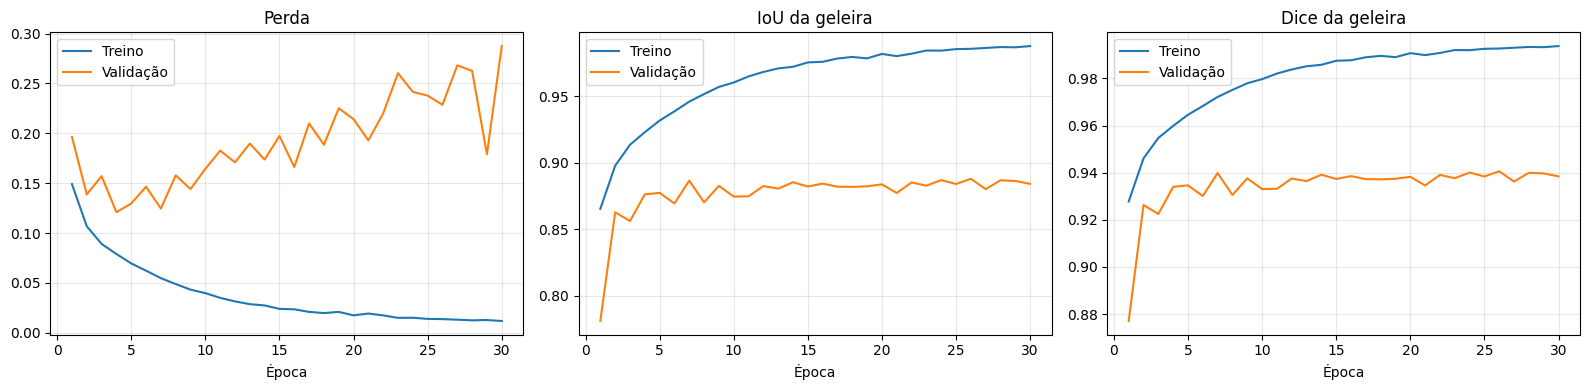

In [ ]:
historico_df = pd.DataFrame(historico)

if historico_df.empty:
    raise RuntimeError(
        'Execute o treinamento ou retome um checkpoint primeiro.'
    )

fig, eixos = plt.subplots(
    1,
    3,
    figsize=(16, 4)
)

for eixo, metrica, titulo in zip(
    eixos,
    ['loss', 'iou_geleira', 'dice_geleira'],
    ['Perda', 'IoU da geleira', 'Dice da geleira']
):
    eixo.plot(
        historico_df['epoca'],
        historico_df[f'treino_{metrica}'],
        label='Treino'
    )

    eixo.plot(
        historico_df['epoca'],
        historico_df[f'validacao_{metrica}'],
        label='Validação'
    )

    eixo.set(
        title=titulo,
        xlabel='Época'
    )

    eixo.grid(alpha=0.3)
    eixo.legend()

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / 'curvas_treinamento.png',
    dpi=160,
    bbox_inches='tight'
)

plt.show()

#16 - Avaliar o melhor modelo

In [ ]:
melhor = torch.load(
    caminho_melhor,
    map_location='cpu',
    weights_only=True,
)

modelo_unet.load_state_dict(melhor['modelo'])
modelo_unet.eval()

print('Época selecionada:', melhor['epoca'])
print('IoU de validação:', melhor['iou_validacao'])

del melhor

resultado_teste, matriz_teste = executar_epoca(
    loaders['fold_test'],
    False,
    'Teste: base completa',
)

display(
    pd.DataFrame([resultado_teste])
    .T.rename(columns={0: 'valor'})
)

matriz_df = pd.DataFrame(
    matriz_teste,
    index=CLASSES,
    columns=CLASSES,
)

display(matriz_df)

matriz_df.to_csv(
    OUTPUT_DIR / 'matriz_confusao_teste.csv'
)

pd.DataFrame([resultado_teste]).to_csv(
    OUTPUT_DIR / 'metricas_teste.csv',
    index=False,
)

salvar_json(
    OUTPUT_DIR / 'metricas_teste.json',
    resultado_teste,
)

Época selecionada: 26
IoU de validação: 0.8878493955684139


Teste: base completa:   0%|          | 0/690 [00:00<?, ?it/s]

,valor
accuracy,0.951783
mean_iou,0.894544
iou_fundo,0.932217
iou_geleira,0.856871
dice_geleira,0.922919
precisao_geleira,0.975048
recall_geleira,0.876081
loss,0.315514
segundos,97.787626
patches,2758


,Fundo,Geleira
Fundo,118851586,1323948
Geleira,7317950,51736526


#17 - Visualizar previsões do teste

Índices das imagens de teste: [0, 919, 1838, 2757]


,indice_patch,arquivo,nome
0,0,g_1266/g_1266_patch_0_xc_128_yc_130.nc,g_1266_patch_0_xc_128_yc_130.nc
1,919,g_3532/g_3532_patch_0_xc_128_yc_157.nc,g_3532_patch_0_xc_128_yc_157.nc
2,1838,g_4009/g_4009_patch_0_xc_128_yc_147.nc,g_4009_patch_0_xc_128_yc_147.nc
3,2757,g_4392/g_4392_patch_5_xc_198_yc_169.nc,g_4392_patch_5_xc_198_yc_169.nc


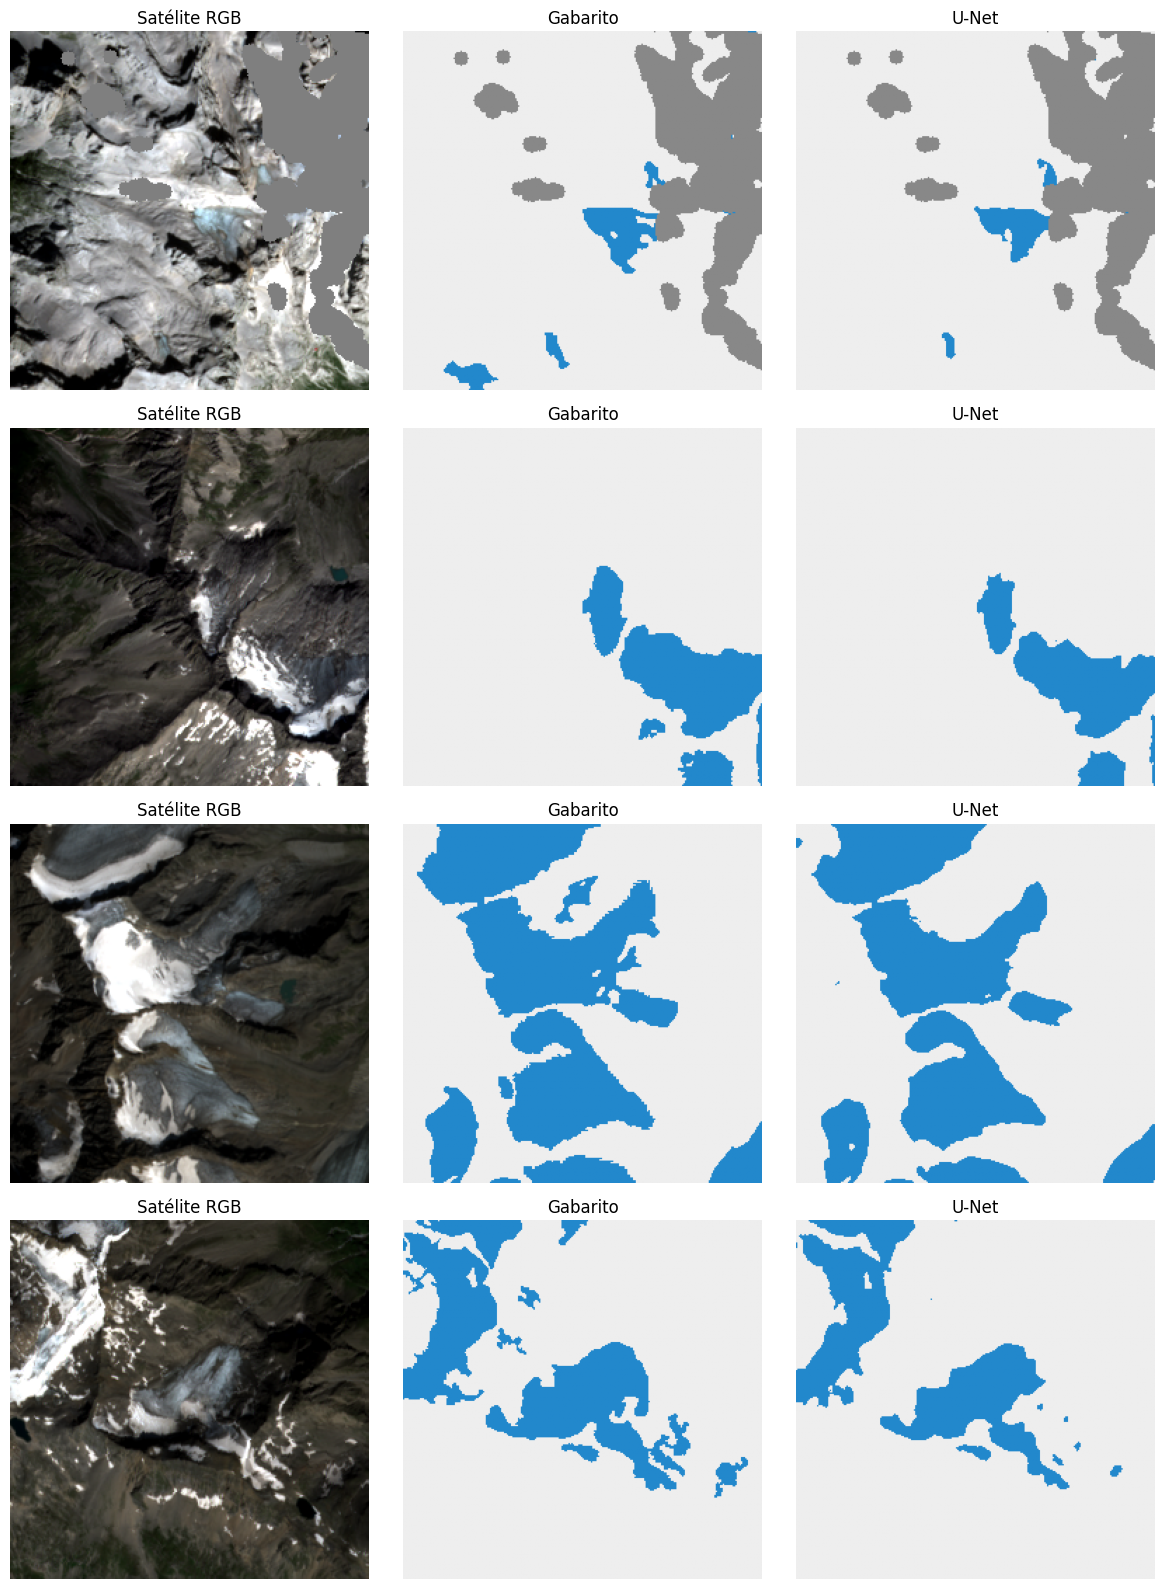

In [ ]:
from matplotlib.colors import ListedColormap


def para_rgb(imagem_normalizada, mascara):
    original = (
        imagem_normalizada * desvio[:, None, None]
        + media[:, None, None]
    )

    rgb = original[
        [BANDAS.index(b) for b in ('B4', 'B3', 'B2')]
    ].transpose(1, 2, 0)

    valido = mascara != IGNORE_INDEX

    if valido.any():
        minimo, maximo = np.percentile(
            rgb[valido],
            [2, 98],
            axis=0
        )

        rgb = np.clip(
            (rgb - minimo)
            / np.maximum(maximo - minimo, 1e-6),
            0,
            1
        )

    else:
        rgb = np.zeros_like(rgb)

    rgb[~valido] = 0.5

    return rgb


cmap_mascara = ListedColormap([
    '#eeeeee',
    '#2288cc'
])

cmap_mascara.set_bad('#888888')

indices_exemplos = np.linspace(
    0,
    len(datasets['fold_test']) - 1,
    min(4, len(datasets['fold_test'])),
    dtype=int
)

exemplos_df = pd.DataFrame([
    {
        'indice_patch': int(i),
        'arquivo': str(datasets['fold_test'].caminhos[int(i)].relative_to(DATA_DIR)),
        'nome': datasets['fold_test'].caminhos[int(i)].name,
    }
    for i in indices_exemplos
])
exemplos_df.to_csv(OUTPUT_DIR / 'exemplos_teste.csv', index=False)
print('Índices das imagens de teste:', indices_exemplos.tolist())
display(exemplos_df)

fig, eixos = plt.subplots(
    len(indices_exemplos),
    3,
    figsize=(12, 4 * len(indices_exemplos)),
    squeeze=False
)

with torch.no_grad():
    for linha, indice in enumerate(indices_exemplos):
        imagem, alvo = datasets['fold_test'][int(indice)]

        with torch.autocast(
            device_type=device.type,
            enabled=USAR_AMP
        ):
            logits = modelo_unet(
                imagem.unsqueeze(0).to(device)
            )

        predicao = (
            logits.argmax(dim=1)[0]
            .cpu()
            .numpy()
        )

        alvo = alvo.numpy()

        predicao = np.ma.array(
            predicao,
            mask=alvo == IGNORE_INDEX
        )

        eixos[linha, 0].imshow(
            para_rgb(imagem.numpy(), alvo)
        )

        eixos[linha, 1].imshow(
            np.ma.masked_equal(alvo, IGNORE_INDEX),
            cmap=cmap_mascara,
            vmin=0,
            vmax=1
        )

        eixos[linha, 2].imshow(
            predicao,
            cmap=cmap_mascara,
            vmin=0,
            vmax=1
        )

        for eixo, titulo in zip(
            eixos[linha],
            ['Satélite RGB', 'Gabarito', 'U-Net']
        ):
            eixo.set_title(titulo)
            eixo.axis('off')

        eixos[linha, 0].set_ylabel(
            datasets['fold_test']
            .caminhos[int(indice)]
            .name
        )

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / 'previsoes_teste.png',
    dpi=160,
    bbox_inches='tight'
)

plt.show()

#17.5 Medição

In [ ]:
@torch.inference_mode()
def aquecer_inferencia(batch_size=1, repeticoes=10):
    modelo_unet.eval()

    x, _ = datasets['fold_test'][0]
    x = (
        x.unsqueeze(0)
        .expand(batch_size, -1, -1, -1)
        .contiguous()
        .to(device)
    )

    with torch.autocast(
        device_type=device.type,
        enabled=USAR_AMP,
    ):
        for _ in range(repeticoes):
            _ = modelo_unet(x).argmax(dim=1)

    if device.type == 'cuda':
        torch.cuda.synchronize(device)


@torch.inference_mode()
def inferir_patch(indice):
    # Arquivo -> normalização -> GPU -> U-Net -> máscara na CPU.
    x, _ = datasets['fold_test'][int(indice)]
    x = x.unsqueeze(0).to(device)

    with torch.autocast(
        device_type=device.type,
        enabled=USAR_AMP,
    ):
        logits = modelo_unet(x)

    return logits.argmax(dim=1).cpu()


modelo_unet.eval()
aquecer_inferencia(batch_size=1)

indices_latencia = np.random.default_rng(SEED).choice(
    len(datasets['fold_test']),
    size=min(N_LATENCIAS, len(datasets['fold_test'])),
    replace=False,
)

latencias_fim_a_fim = []
latencias_modelo = []

with MonitorRecursos('Latencia_batch_1') as monitor_latencia:
    for indice in tqdm(
        indices_latencia,
        desc='Latência por imagem',
    ):
        if device.type == 'cuda':
            torch.cuda.synchronize(device)

        inicio = time.perf_counter()
        predicao = inferir_patch(indice)

        if device.type == 'cuda':
            torch.cuda.synchronize(device)

        latencias_fim_a_fim.append(
            (time.perf_counter() - inicio) * 1000
        )
        del predicao

        # Modelo + argmax, com entrada já no dispositivo.
        x, _ = datasets['fold_test'][int(indice)]
        x = x.unsqueeze(0).to(device)

        if device.type == 'cuda':
            torch.cuda.synchronize(device)

        inicio = time.perf_counter()

        with torch.inference_mode(), torch.autocast(
            device_type=device.type,
            enabled=USAR_AMP,
        ):
            saida = modelo_unet(x).argmax(dim=1)

        if device.type == 'cuda':
            torch.cuda.synchronize(device)

        latencias_modelo.append(
            (time.perf_counter() - inicio) * 1000
        )
        del x, saida


latencias_raw = pd.DataFrame({
    'indice_patch': indices_latencia,
    'fim_a_fim_ms': latencias_fim_a_fim,
    'modelo_e_argmax_ms': latencias_modelo,
})

latencias_raw.to_csv(
    MEDICOES_DIR / 'latencias_amostras.csv',
    index=False,
)

latencias_resumo = pd.DataFrame([
    {
        'escopo': escopo,
        'batch_size': 1,
        'n': len(valores),
        'media_ms': np.mean(valores),
        'p50_ms': np.percentile(valores, 50),
        'p95_ms': np.percentile(valores, 95),
        'p99_ms': np.percentile(valores, 99),
        'desvio_ms': (
            np.std(valores, ddof=1)
            if len(valores) > 1 else np.nan
        ),
    }
    for escopo, valores in [
        ('fim_a_fim', latencias_fim_a_fim),
        ('modelo_e_argmax', latencias_modelo),
    ]
])

latencias_resumo.to_csv(
    MEDICOES_DIR / 'latencias_resumo.csv',
    index=False,
)

display(latencias_resumo)

Latência por imagem:   0%|          | 0/200 [00:00<?, ?it/s]

,escopo,batch_size,n,media_ms,p50_ms,p95_ms,p99_ms,desvio_ms
0,fim_a_fim,1,200,48.937828,48.850472,54.961471,61.919561,3.863906
1,modelo_e_argmax,1,200,15.093470,15.865057,16.181686,16.523172,1.365110


Benchmark_b4_w1_r1:   0%|          | 0/690 [00:00<?, ?it/s]

Benchmark_b2_w2_r1:   0%|          | 0/1379 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d9e5eb95120>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    Exception ignored in: self._shutdown_workers()
<function _MultiProcessingDataLoaderIter.__del__ at 0x7d9e5eb95120>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only te

Benchmark_b4_w0_r1:   0%|          | 0/690 [00:00<?, ?it/s]

Benchmark_b4_w2_r1:   0%|          | 0/690 [00:00<?, ?it/s]

Benchmark_b1_w2_r1:   0%|          | 0/2758 [00:00<?, ?it/s]

... (18 outputs left out)

Benchmark_b4_w2_r3:   0%|          | 0/690 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d9e5eb95120>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
Exception ignored in:   File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    <function _MultiProcessingDataLoaderIter.__del__ at 0x7d9e5eb95120>assert self._parent_pid == os.getpid(), 'can only test a child process'

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
AssertionError    self._shutdown_workers(): can only test a child process

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Benchmark_b8_w2_r3:   0%|          | 0/345 [00:00<?, ?it/s]

,batch_size,num_workers,repeticoes,tempo_medio_s,tempo_desvio_s,throughput_patch_s,ram_vm_pico_gib,memoria_alocada_gpu_pico_gib,gpu_media_pct,energia_gpu_media_j,energia_gpu_media_j_por_patch,speedup_leitura_vs_workers_0
0,1,2,3,94.672364,0.767184,29.133328,3.197838,0.607255,35.670503,4211.488000,1.527008,NaN
1,2,2,3,90.968923,0.293746,30.318257,3.301186,0.681710,31.289537,3933.695000,1.426285,NaN
2,4,0,3,137.448460,5.377303,20.086626,3.059563,0.831193,24.877831,5220.320667,1.892792,1.000000
3,4,1,3,112.822931,0.448746,24.445643,3.215740,0.831193,28.746028,4545.155333,1.647990,1.218267
4,4,2,3,88.107527,0.684627,31.303924,3.219242,0.831193,32.830524,3658.829333,1.326624,1.560008
5,8,2,3,86.469570,0.741731,31.897176,3.417656,1.128545,27.208880,4298.451333,1.558539,NaN


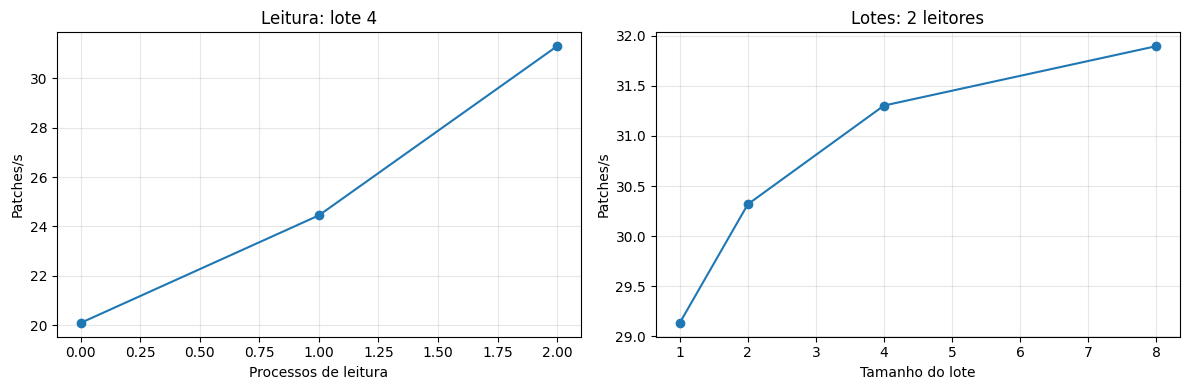

In [ ]:
# Todos os patches do teste e os mesmos pesos em cada configuração.
# Repete somente avaliação; não altera os pesos.
# Mede leitores CPU e tamanho de lote na mesma GPU.

try:
    cpus_disponiveis = len(
        psutil.Process().cpu_affinity()
    )
except (psutil.Error, AttributeError):
    cpus_disponiveis = psutil.cpu_count() or 1

workers_bench = sorted({
    0, 1, min(2, cpus_disponiveis)
})
worker_referencia = max(workers_bench)

configuracoes_bench = sorted(
    {(BATCH_SIZE, w) for w in workers_bench}
    | {(b, worker_referencia) for b in BATCHES_BENCH}
)

registros_bench = []
ordem_bench = random.Random(SEED)

with MonitorRecursos(
    'Escalabilidade_completa',
    medir_alocador=False,
) as monitor_escala:

    for repeticao in range(1, REPETICOES_BENCH + 1):
        ordem = list(configuracoes_bench)
        ordem_bench.shuffle(ordem)

        for batch, workers in ordem:
            aquecer_inferencia(batch_size=batch)

            loader_bench = DataLoader(
                datasets['fold_test'],
                batch_size=batch,
                shuffle=False,
                num_workers=workers,
                pin_memory=device.type == 'cuda',
                persistent_workers=False,
                drop_last=False,
            )

            nome = (
                f'Benchmark_b{batch}_w{workers}_r{repeticao}'
            )

            resultado, _ = executar_epoca(
                loader_bench, False, nome
            )

            resultado.update(repeticao=repeticao)
            registros_bench.append(resultado)

            pd.DataFrame(registros_bench).to_csv(
                MEDICOES_DIR / 'benchmarks_amostras.csv',
                index=False,
            )

            del loader_bench


benchmarks = pd.DataFrame(registros_bench)

escala_resumo = benchmarks.groupby(
    ['batch_size', 'num_workers'],
    as_index=False,
).agg(
    repeticoes=('segundos', 'count'),
    tempo_medio_s=('segundos', 'mean'),
    tempo_desvio_s=('segundos', 'std'),
    throughput_patch_s=('patches_por_segundo', 'mean'),
    ram_vm_pico_gib=('ram_vm_pico_gib', 'max'),
    memoria_alocada_gpu_pico_gib=('pico_memoria_gpu_gib', 'max'),
    gpu_media_pct=('gpu_media_pct', 'mean'),
    energia_gpu_media_j=('energia_gpu_j', 'mean'),
    energia_gpu_media_j_por_patch=('energia_gpu_j_por_patch', 'mean'),
)

tempo_serial = escala_resumo.loc[
    (escala_resumo['batch_size'] == BATCH_SIZE)
    & (escala_resumo['num_workers'] == 0),
    'tempo_medio_s',
].iloc[0]

escala_resumo['speedup_leitura_vs_workers_0'] = np.where(
    escala_resumo['batch_size'] == BATCH_SIZE,
    tempo_serial / escala_resumo['tempo_medio_s'],
    np.nan,
)

escala_resumo.to_csv(
    MEDICOES_DIR / 'escalabilidade_resumo.csv',
    index=False,
)

display(escala_resumo)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

leitura = escala_resumo[
    escala_resumo['batch_size'] == BATCH_SIZE
].sort_values('num_workers')

lotes = escala_resumo[
    escala_resumo['num_workers'] == worker_referencia
].sort_values('batch_size')

axes[0].plot(
    leitura['num_workers'],
    leitura['throughput_patch_s'],
    marker='o',
)
axes[0].set(
    xlabel='Processos de leitura',
    ylabel='Patches/s',
    title=f'Leitura: lote {BATCH_SIZE}',
)

axes[1].plot(
    lotes['batch_size'],
    lotes['throughput_patch_s'],
    marker='o',
)
axes[1].set(
    xlabel='Tamanho do lote',
    ylabel='Patches/s',
    title=f'Lotes: {worker_referencia} leitores',
)

for ax in axes:
    ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    MEDICOES_DIR / 'escalabilidade.png',
    dpi=150,
)

plt.show()

In [ ]:
altura, largura = x_exemplo.shape[-2:]

volume_dados = pd.DataFrame([
    {
        'grupo': fold,
        'patches_unicos': len(grupos[fold]),
        'arquivos_nc_bytes': sum(
            p.stat().st_size for p in grupos[fold]
        ),
        'arquivos_nc_gib': sum(
            p.stat().st_size for p in grupos[fold]
        ) / 2**30,
        'pixels_nominais': (
            len(grupos[fold]) * altura * largura
        ),
        'entradas_float32_gib': (
            len(grupos[fold])
            * len(BANDAS) * altura * largura * 4 / 2**30
        ),
    }
    for fold in FOLDS
])

volume_dados.to_csv(
    MEDICOES_DIR / 'volume_dados.csv',
    index=False,
)

h = pd.DataFrame(historico)
resumo_fases = []

for prefixo in ['treino', 'validacao']:
    segundos = h[f'{prefixo}_segundos'].sum()
    patches = int(h[f'{prefixo}_patches'].sum())

    # Consumo desconhecido permanece indefinido.
    energia = h[f'{prefixo}_energia_gpu_j'].sum(
        min_count=len(h)
    )

    resumo_fases.append({
        'fase': prefixo,
        'epocas': len(h),
        'segundos': segundos,
        'horas': segundos / 3600,
        'patches_apresentados': patches,
        'throughput_patch_s': (
            patches / max(segundos, 1e-9)
        ),
        'energia_gpu_j': energia,
        'energia_gpu_kwh': energia / 3_600_000,
        'energia_gpu_j_por_patch': energia / patches,
        'cpu_vm_media_pct': np.average(
            h[f'{prefixo}_cpu_vm_media_pct'],
            weights=h[f'{prefixo}_segundos'],
        ),
        'gpu_media_pct': np.average(
            h[f'{prefixo}_gpu_media_pct'],
            weights=h[f'{prefixo}_segundos'],
        ),
        'ram_vm_pico_gib': h[
            f'{prefixo}_ram_vm_pico_gib'
        ].max(),
        'pico_memoria_gpu_gib': h[
            f'{prefixo}_pico_memoria_gpu_gib'
        ].max(),
    })

resumo_fases.append({
    'fase': 'teste',
    'segundos': resultado_teste['segundos'],
    'horas': resultado_teste['segundos'] / 3600,
    'patches_apresentados': resultado_teste['patches'],
    'throughput_patch_s': resultado_teste['patches_por_segundo'],
    **{
        k: v
        for k, v in resultado_teste.items()
        if k.startswith((
            'energia_gpu_', 'cpu_vm_', 'gpu_',
            'ram_vm_', 'pico_memoria_gpu',
        ))
    },
})

resumo_df = pd.DataFrame(resumo_fases)

resumo_df.to_csv(
    MEDICOES_DIR / 'resumo_fases.csv',
    index=False,
)

salvar_json(
    MEDICOES_DIR / 'qualidade_teste.json',
    {
        k: resultado_teste[k]
        for k in [
            'accuracy', 'mean_iou', 'iou_fundo', 'iou_geleira',
            'dice_geleira', 'precisao_geleira', 'recall_geleira',
            'loss', 'pixels_validos', 'pixels_ignorados',
        ]
    },
)

# Evita contar o treinamento completo novamente junto às suas épocas.
fases_externas = [
    'Inventario_e_split',
    'Normalizacao',
    'Inicializacao_modelo',
    'Treinamento_completo',
    'Teste: base completa',
    'Latencia_batch_1',
    'Escalabilidade_completa',
]

externas = pd.DataFrame(FASES)
externas = externas[
    externas['fase'].isin(fases_externas)
]

salvar_json(
    MEDICOES_DIR / 'escopo_medicoes.json',
    {
        'split': SPLIT,
        'total_patches_unicos': int(
            volume_dados['patches_unicos'].sum()
        ),
        'patches_treino_apresentados': int(
            h['treino_patches'].sum()
        ),
        'patches_validacao_apresentados': int(
            h['validacao_patches'].sum()
        ),
        'tempo_soma_fases_externas_s': float(
            externas['segundos_monitorados'].sum()
        ),
        'energia_soma_fases_externas_kwh': float(
            externas['energia_gpu_kwh'].sum(
                min_count=len(externas)
            )
        ),
        'energia_escopo': (
            'GPU inteira, incluindo espera por dados; '
            'exclui CPU, discos e refrigeracao'
        ),
        'tempo_escopo': (
            'Fases nomeadas; exclui download, extracao, '
            'instalacao e pausas entre celulas'
        ),
        'throughput_escopo': (
            'Avaliacao completa: leitura, normalizacao, '
            'transferencias, modelo, perda e metricas'
        ),
        'latencia_escopo': (
            'Batch 1 apos aquecimento; fim a fim '
            'e modelo+argmax medidos separadamente'
        ),
        'escalabilidade_escopo': (
            'Leitores CPU e tamanho do lote na mesma GPU; '
            'nao mede multiplas GPUs/nos'
        ),
        'volume_escopo': (
            'Patches podem se sobrepor; bytes NC no disco '
            'e volume logico float32 nao sao I/O fisico'
        ),
    },
)

display(volume_dados)
display(resumo_df)

print('Arquivos de medição:', MEDICOES_DIR.resolve())

,grupo,patches_unicos,arquivos_nc_bytes,arquivos_nc_gib,pixels_nominais,entradas_float32_gib
0,fold_train,7409,35862916504,33.399944,485556224,23.514893
1,fold_valid,1273,6161386892,5.738239,83427328,4.040283
2,fold_test,2758,13348056014,12.431346,180748288,8.753418


,fase,epocas,segundos,horas,patches_apresentados,throughput_patch_s,energia_gpu_j,energia_gpu_kwh,energia_gpu_j_por_patch,cpu_vm_media_pct,gpu_media_pct,ram_vm_pico_gib,pico_memoria_gpu_gib,cpu_vm_pico_pct,gpu_pico_pct,energia_gpu_wh,energia_gpu_metodo,energia_gpu_contador_j,energia_gpu_integrada_j,pico_memoria_gpu_reservada_gib
0,treino,30.0,9435.820308,2.621061,222270,23.555981,588230.828,0.163397,2.646470,95.987299,68.575250,2.746185,1.181420,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,validacao,30.0,1385.949477,0.384986,38190,27.555117,57836.399,0.016066,1.514438,87.885355,29.258175,2.738647,0.834855,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,teste,NaN,97.787626,0.027163,2758,28.203977,4117.304,0.001144,1.492859,88.186458,28.540816,2.730721,0.830949,93.0,42.0,1.143696,contador_nvml,4117.304,3973.658128,1.400391


Arquivos de medição: /content/resultados_unet_split1_metrificado_20261015T170636Z_05c22191/medicoes


#17.6 - Vizualização das metricas

Métrica,Resultado
IoU de geleira,"85,69%"
Dice / F1 de geleira,"92,29%"
Precisão de geleira,"97,50%"
Recall de geleira,"87,61%"
IoU médio das duas classes,"89,45%"
IoU de fundo,"93,22%"
Acurácia dos pixels,"95,18%"


Etapa,Tempo,Patches processados,Patches/s,Energia GPU (Wh),Energia GPU (J/patch)
Treino (todas as épocas),2 h 37 min 16 s,222.270,"23,56","163,40","2,646"
Validação (todas as épocas),23 min 06 s,38.190,"27,56","16,07","1,514"
Teste (uma passagem),1 min 38 s,2.758,"28,20","1,14","1,493"


Etapa,CPU VM* (%),GPU média (%),Pico RAM VM (GiB),Pico GPU PyTorch (GiB)
Treino (todas as épocas),"95,99","68,58","2,75","1,18"
Validação (todas as épocas),"87,89","29,26","2,74","0,83"
Teste (uma passagem),"88,19","28,54","2,73","0,83"


Medida,Valor
Pico de VRAM total da GPU (NVML),"1,97 GiB"
Pico de memória reservada pelo PyTorch,"1,40 GiB"
Pico de memória de tensores PyTorch,"0,83 GiB"
Potência média da GPU (amostras integradas),"40,63 W"
Potência máxima amostrada da GPU,"65,30 W"
Tráfego recebido pela VM,"0,069 MiB"
Tráfego enviado pela VM,"0,719 MiB"


Escopo,Amostras,Média (ms),Mediana (ms),P95 (ms),P99 (ms)
Arquivo → máscara na CPU,200,"48,94","48,85","54,96","61,92"
Modelo + argmax (entrada no dispositivo),200,"15,09","15,87","16,18","16,52"


Lote,Leitores,Repetições,Tempo médio ± DP (s),Patches/s,Energia GPU (J/patch),Pico GPU PyTorch (GiB),Speedup leitura
1,2,3,"94,67 ± 0,77","29,13","1,527","0,61",—
2,2,3,"90,97 ± 0,29","30,32","1,426","0,68",—
4,0,3,"137,45 ± 5,38","20,09","1,893","0,83","1,00×"
4,1,3,"112,82 ± 0,45","24,45","1,648","0,83","1,22×"
4,2,3,"88,11 ± 0,68","31,30","1,327","0,83","1,56×"
8,2,3,"86,47 ± 0,74","31,90","1,559","1,13",—


Grupo,Patches únicos,Arquivos NC (GiB),Entradas float32 (GiB)
Treino,7.409,"33,40","23,51"
Validação,1.273,"5,74","4,04"
Teste,2.758,"12,43","8,75"


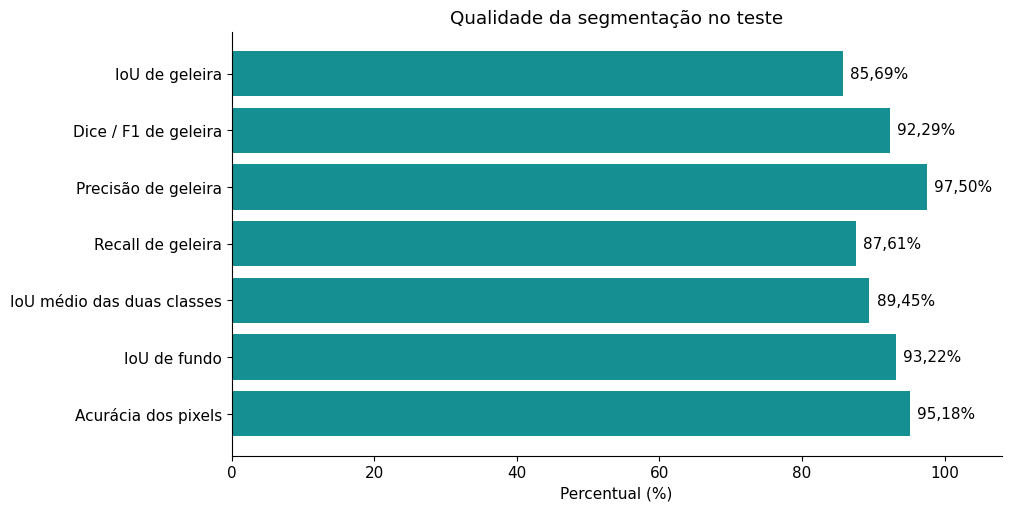

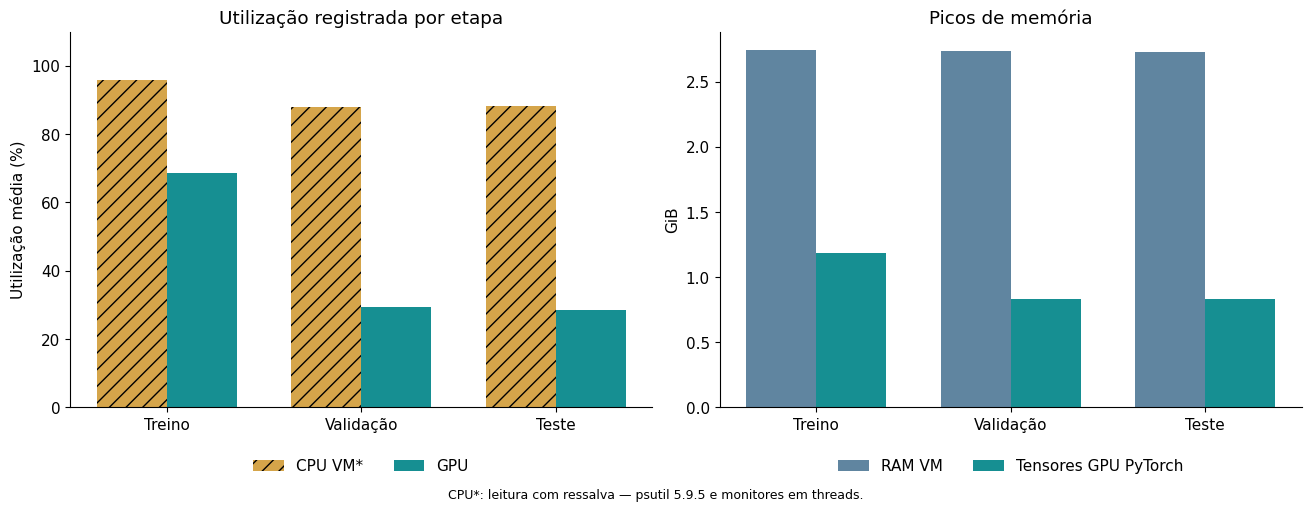

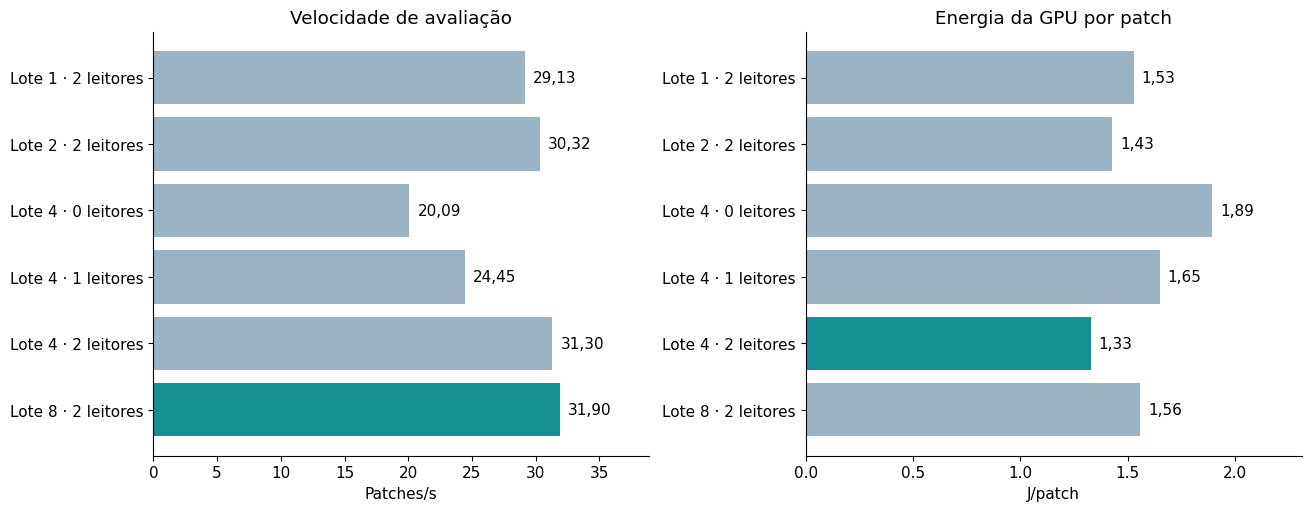

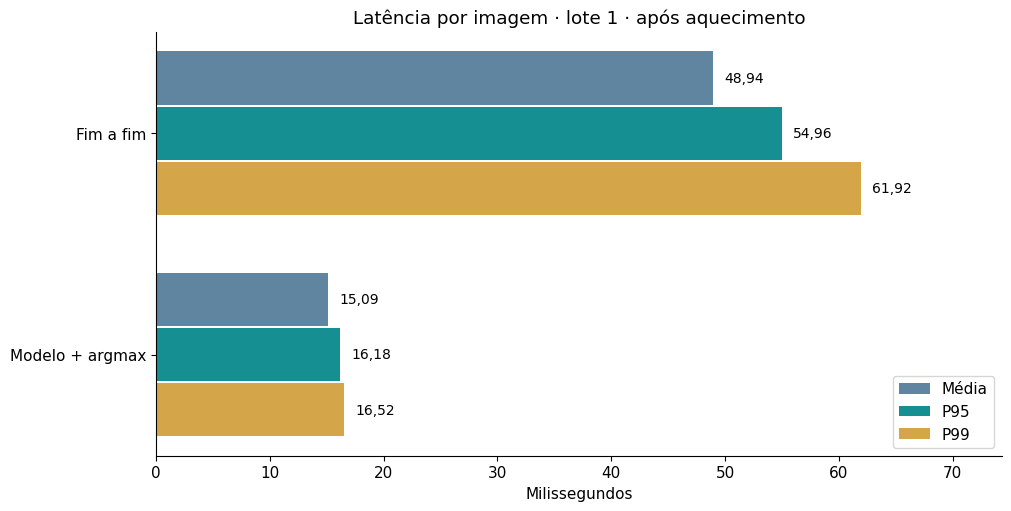

Painel gerado com as métricas já salvas.
Gráficos e tabelas adicionais em: /content/resultados_unet_split1_metrificado_20261015T170636Z_05c22191/medicoes


In [ ]:
from pathlib import Path
from IPython.display import HTML, display

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Lê as métricas da execução existente.
pasta = Path(MEDICOES_DIR)

teste = json.loads(
    (pasta.parent / 'metricas_teste.json').read_text()
)
total = json.loads(
    (pasta / 'treinamento_completo.json').read_text()
)
hardware_painel = json.loads(
    (pasta / 'hardware.json').read_text()
)

fases_painel = pd.read_csv(pasta / 'resumo_fases.csv')
latencia_painel = pd.read_csv(pasta / 'latencias_resumo.csv')
escala_painel = pd.read_csv(pasta / 'escalabilidade_resumo.csv')
volume_painel = pd.read_csv(pasta / 'volume_dados.csv')


# ============================================================
# FORMATAÇÃO
# ============================================================

def numero_br(valor, casas=2):
    if pd.isna(valor):
        return '—'

    return (
        f'{float(valor):,.{casas}f}'
        .replace(',', '#')
        .replace('.', ',')
        .replace('#', '.')
    )


def tempo_legivel(segundos):
    if pd.isna(segundos):
        return '—'

    segundos = int(round(float(segundos)))
    horas, resto = divmod(segundos, 3600)
    minutos, segundos = divmod(resto, 60)

    if horas:
        return (
            f'{horas} h '
            f'{minutos:02d} min '
            f'{segundos:02d} s'
        )

    return f'{minutos} min {segundos:02d} s'


def tabela_painel(titulo, tabela, nota=''):
    display(HTML(
        '<div class="unet-painel">'
        f'<h3>{titulo}</h3>'
        '<div class="unet-tabela">'
        f'{tabela.to_html(index=False, escape=True)}'
        '</div>'
        f'<p class="unet-nota">{nota}</p>'
        '</div>'
    ))


estilo = """
<style>
.unet-painel {
    max-width: 1150px;
    padding: 16px;
    margin: 12px 0;
    background: #ffffff;
    border: 1px solid #e3ebef;
    border-radius: 10px;
    color: #183042;
    font-family: Arial, sans-serif;
}
.unet-painel h2 {
    margin: 0 0 6px;
    font-size: 25px;
}
.unet-painel h3 {
    margin: 8px 0 12px;
    font-size: 19px;
}
.unet-cartoes {
    display: flex;
    flex-wrap: wrap;
    gap: 12px;
    margin: 18px 0;
}
.unet-cartao {
    flex: 1 1 210px;
    padding: 18px;
    border: 1px solid #dbe5eb;
    border-radius: 10px;
    background: #f5f9fb;
}
.unet-cartao small {
    display: block;
    color: #526b7b;
    font-size: 13px;
}
.unet-cartao strong {
    display: block;
    font-size: 26px;
    margin: 9px 0;
    color: #087f83;
}
.unet-tabela {
    overflow-x: auto;
}
.unet-tabela table {
    border-collapse: collapse;
    width: 100%;
    font-size: 14px;
}
.unet-tabela th {
    background: #183b50;
    color: white;
    padding: 11px;
    text-align: left;
}
.unet-tabela td {
    padding: 10px 11px;
    border-bottom: 1px solid #e3ebef;
    text-align: right;
    font-variant-numeric: tabular-nums;
}
.unet-tabela td:first-child {
    text-align: left;
}
.unet-tabela tr:nth-child(even) {
    background: #f3f7f9;
}
.unet-nota {
    font-size: 13px;
    line-height: 1.5;
    color: #526b7b;
}
</style>
"""


# ============================================================
# CARTÕES COM OS PRINCIPAIS RESULTADOS
# ============================================================

lat_fim = (
    latencia_painel.set_index('escopo')
    .loc['fim_a_fim']
)

cartoes = [
    (
        'IoU de geleira',
        numero_br(100 * teste['iou_geleira']) + '%',
        'Qualidade no teste',
    ),
    (
        'Dice de geleira',
        numero_br(100 * teste['dice_geleira']) + '%',
        'Qualidade no teste',
    ),
    (
        'Treinamento completo',
        tempo_legivel(total['segundos_monitorados']),
        'Treino + validação + checkpoints',
    ),
    (
        'Energia da GPU no treinamento',
        numero_br(total['energia_gpu_kwh'] * 1000) + ' Wh',
        'GPU inteira; método: ' + str(total['energia_gpu_metodo']),
    ),
    (
        'Velocidade no teste',
        numero_br(teste['patches_por_segundo']) + ' patches/s',
        'Pipeline completo de avaliação',
    ),
    (
        'Latência média por imagem',
        numero_br(lat_fim['media_ms']) + ' ms',
        'Fim a fim, lote 1, após aquecimento',
    ),
]

html_cartoes = ''.join(
    '<div class="unet-cartao">'
    f'<small>{nome}</small>'
    f'<strong>{valor}</strong>'
    f'<small>{nota}</small>'
    '</div>'
    for nome, valor, nota in cartoes
)

display(HTML(
    estilo
    + '<div class="unet-painel">'
    + '<h2>U-Net · resultados da execução</h2>'
    + '<p class="unet-nota">'
    + f'{hardware_painel.get("gpu", "GPU")} · split_1 · '
    + numero_br(volume_painel['patches_unicos'].sum(), 0)
    + ' patches únicos</p>'
    + f'<div class="unet-cartoes">{html_cartoes}</div>'
    + '</div>'
))


# ============================================================
# QUALIDADE DA SEGMENTAÇÃO
# ============================================================

qualidade_itens = [
    ('IoU de geleira', 'iou_geleira'),
    ('Dice / F1 de geleira', 'dice_geleira'),
    ('Precisão de geleira', 'precisao_geleira'),
    ('Recall de geleira', 'recall_geleira'),
    ('IoU médio das duas classes', 'mean_iou'),
    ('IoU de fundo', 'iou_fundo'),
    ('Acurácia dos pixels', 'accuracy'),
]

qualidade_tabela = pd.DataFrame([
    {
        'Métrica': nome,
        'Resultado': numero_br(100 * teste[chave]) + '%',
    }
    for nome, chave in qualidade_itens
])

tabela_painel(
    'Qualidade da segmentação',
    qualidade_tabela,
    f'Perda no teste: {numero_br(teste["loss"], 4)}. '
    f'Avaliação sobre {numero_br(teste["pixels_validos"], 0)} '
    'pixels válidos. '
    f'{numero_br(100 * (1 - teste["recall_geleira"]))}% '
    'dos pixels reais de geleira não foram detectados.',
)


# ============================================================
# TEMPO, THROUGHPUT E ENERGIA
# ============================================================

etapas = {
    'treino': 'Treino (todas as épocas)',
    'validacao': 'Validação (todas as épocas)',
    'teste': 'Teste (uma passagem)',
}

tempo_tabela = pd.DataFrame([
    {
        'Etapa': etapas.get(r.fase, r.fase),
        'Tempo': tempo_legivel(r.segundos),
        'Patches processados': numero_br(r.patches_apresentados, 0),
        'Patches/s': numero_br(r.throughput_patch_s),
        'Energia GPU (Wh)': numero_br(r.energia_gpu_j / 3600),
        'Energia GPU (J/patch)': numero_br(
            r.energia_gpu_j_por_patch, 3
        ),
    }
    for r in fases_painel.itertuples()
])

tabela_painel(
    'Tempo e volume processado',
    tempo_tabela,
    'Patches processados incluem reapresentações nas épocas. '
    'O total do treinamento nos cartões inclui validação e '
    'checkpoints; não deve ser somado novamente às etapas '
    'desta tabela.',
)


# ============================================================
# CPU, GPU E MEMÓRIA
# ============================================================

cpu_versao = tuple(
    int(p)
    for p in str(hardware_painel.get('psutil', '0')).split('.')[:3]
)

cpu_ressalva = cpu_versao < (5, 9, 6)

nota_cpu = ''

if cpu_ressalva:
    nota_cpu = (
        'CPU*: esta execução usou psutil '
        + str(hardware_painel.get('psutil'))
        + ' com monitores em threads. A segurança de '
        'cpu_percent para chamadas concorrentes foi adicionada '
        'em 5.9.6; trate os percentuais de CPU como leituras '
        'registradas com ressalva. '
        'Referência: '
        'https://psutil.readthedocs.io/en/stable/#psutil.cpu_percent. '
    )

recursos_tabela = pd.DataFrame([
    {
        'Etapa': etapas.get(r.fase, r.fase),
        'CPU VM* (%)': numero_br(r.cpu_vm_media_pct),
        'GPU média (%)': numero_br(r.gpu_media_pct),
        'Pico RAM VM (GiB)': numero_br(r.ram_vm_pico_gib),
        'Pico GPU PyTorch (GiB)': numero_br(
            r.pico_memoria_gpu_gib
        ),
    }
    for r in fases_painel.itertuples()
])

tabela_painel(
    'Uso de recursos por etapa',
    recursos_tabela,
    nota_cpu
    + 'CPU e RAM são da VM inteira. GPU PyTorch = memória '
    'ocupada por tensores; picos de RAM são amostrados.',
)

detalhes_teste = pd.DataFrame([
    {
        'Medida': 'Pico de VRAM total da GPU (NVML)',
        'Valor': numero_br(teste['vram_gpu_pico_gib']) + ' GiB',
    },
    {
        'Medida': 'Pico de memória reservada pelo PyTorch',
        'Valor': numero_br(
            teste['pico_memoria_gpu_reservada_gib']
        ) + ' GiB',
    },
    {
        'Medida': 'Pico de memória de tensores PyTorch',
        'Valor': numero_br(
            teste['pico_memoria_gpu_gib']
        ) + ' GiB',
    },
    {
        'Medida': 'Potência média da GPU (amostras integradas)',
        'Valor': numero_br(
            teste['potencia_gpu_media_w']
        ) + ' W',
    },
    {
        'Medida': 'Potência máxima amostrada da GPU',
        'Valor': numero_br(
            teste['potencia_gpu_pico_w']
        ) + ' W',
    },
    {
        'Medida': 'Tráfego recebido pela VM',
        'Valor': numero_br(
            teste['rede_vm_recebida_mib'], 3
        ) + ' MiB',
    },
    {
        'Medida': 'Tráfego enviado pela VM',
        'Valor': numero_br(
            teste['rede_vm_enviada_mib'], 3
        ) + ' MiB',
    },
])

tabela_painel(
    'Memória, potência e rede durante o teste',
    detalhes_teste,
    'Energia cobre a GPU inteira, incluindo espera por dados; '
    'CPU, discos e refrigeração ficam fora da medição. '
    'O tráfego inclui outras atividades da VM. Contador NVML '
    'e integração de potência são métodos distintos.',
)


# ============================================================
# LATÊNCIA
# ============================================================

latencia_nomes = {
    'fim_a_fim': 'Arquivo → máscara na CPU',
    'modelo_e_argmax': 'Modelo + argmax (entrada no dispositivo)',
}

latencia_tabela = pd.DataFrame([
    {
        'Escopo': latencia_nomes.get(r.escopo, r.escopo),
        'Amostras': int(r.n),
        'Média (ms)': numero_br(r.media_ms),
        'Mediana (ms)': numero_br(r.p50_ms),
        'P95 (ms)': numero_br(r.p95_ms),
        'P99 (ms)': numero_br(r.p99_ms),
    }
    for r in latencia_painel.itertuples()
])

tabela_painel(
    'Latência por imagem',
    latencia_tabela,
    'Lote 1, após aquecimento. P95 é o tempo abaixo do qual '
    'ficaram 95% das observações. Dividir o tempo de um teste '
    'com lotes pelo número de patches produz custo amortizado, '
    'não latência individual.',
)


# ============================================================
# COMPARAÇÃO DOS BENCHMARKS
# ============================================================

escala_painel = (
    escala_painel
    .sort_values(['batch_size', 'num_workers'])
    .reset_index(drop=True)
)

escala_tabela = pd.DataFrame([
    {
        'Lote': int(r.batch_size),
        'Leitores': int(r.num_workers),
        'Repetições': int(r.repeticoes),
        'Tempo médio ± DP (s)': (
            numero_br(r.tempo_medio_s)
            + ' ± '
            + numero_br(r.tempo_desvio_s)
        ),
        'Patches/s': numero_br(r.throughput_patch_s),
        'Energia GPU (J/patch)': numero_br(
            r.energia_gpu_media_j_por_patch, 3
        ),
        'Pico GPU PyTorch (GiB)': numero_br(
            r.memoria_alocada_gpu_pico_gib
        ),
        'Speedup leitura': (
            numero_br(r.speedup_leitura_vs_workers_0) + '×'
            if pd.notna(r.speedup_leitura_vs_workers_0)
            else '—'
        ),
    }
    for r in escala_painel.itertuples()
])

mais_rapido = escala_painel.loc[
    escala_painel['throughput_patch_s'].idxmax()
]

mais_economico = escala_painel.loc[
    escala_painel['energia_gpu_media_j_por_patch'].idxmin()
]

tabela_painel(
    'Comparação das configurações de avaliação',
    escala_tabela,
    f'Mais rápida observada: lote {int(mais_rapido.batch_size)}, '
    f'{int(mais_rapido.num_workers)} leitores. '
    'Menor energia por patch observada: '
    f'lote {int(mais_economico.batch_size)}, '
    f'{int(mais_economico.num_workers)} leitores. '
    'Mesma GPU, mesmos pesos e todos os patches do teste '
    'em cada repetição. DP = desvio padrão. Speedup de leitura '
    'compara apenas configurações com o lote de referência fixo.',
)


# ============================================================
# VOLUME DA BASE
# ============================================================

grupos_nomes = {
    'fold_train': 'Treino',
    'fold_valid': 'Validação',
    'fold_test': 'Teste',
}

volume_tabela = pd.DataFrame([
    {
        'Grupo': grupos_nomes.get(r.grupo, r.grupo),
        'Patches únicos': numero_br(r.patches_unicos, 0),
        'Arquivos NC (GiB)': numero_br(r.arquivos_nc_gib),
        'Entradas float32 (GiB)': numero_br(
            r.entradas_float32_gib
        ),
    }
    for r in volume_painel.itertuples()
])

tabela_painel(
    'Volume único da base',
    volume_tabela,
    f'Total: {numero_br(volume_painel["patches_unicos"].sum(), 0)} '
    'patches e '
    f'{numero_br(volume_painel["arquivos_nc_gib"].sum())} GiB '
    'em arquivos NC. Patches podem se sobrepor. O volume lógico '
    'float32 não representa a RAM ocupada simultaneamente.',
)


# ============================================================
# GRÁFICOS
# ============================================================

figuras_painel = []

with plt.rc_context({
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
}):

    # 1. Qualidade da segmentação.
    fig, ax = plt.subplots(
        figsize=(10, 5),
        layout='constrained',
    )

    valores = [
        100 * teste[chave]
        for _, chave in qualidade_itens
    ]

    ax.barh(
        [nome for nome, _ in qualidade_itens],
        valores,
        color='#168f92',
    )
    ax.invert_yaxis()

    ax.set(
        xlim=(0, 108),
        xlabel='Percentual (%)',
        title='Qualidade da segmentação no teste',
    )

    for i, valor in enumerate(valores):
        ax.text(
            valor + 1,
            i,
            numero_br(valor) + '%',
            va='center',
        )

    figuras_painel.append(('painel_qualidade.png', fig))

    # 2. CPU, GPU e memória.
    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 5),
        layout='constrained',
    )

    x = np.arange(len(fases_painel))
    nomes = ['Treino', 'Validação', 'Teste']

    axes[0].bar(
        x - .18,
        fases_painel['cpu_vm_media_pct'],
        .36,
        label='CPU VM*',
        color='#d5a54a',
        hatch='//' if cpu_ressalva else None,
    )

    axes[0].bar(
        x + .18,
        fases_painel['gpu_media_pct'],
        .36,
        label='GPU',
        color='#168f92',
    )

    axes[0].set(
        xticks=x,
        xticklabels=nomes,
        ylim=(0, 110),
        ylabel='Utilização média (%)',
        title='Utilização registrada por etapa',
    )

    axes[0].legend(
        loc='upper center',
        bbox_to_anchor=(.5, -.10),
        ncol=2,
        frameon=False,
    )

    axes[1].bar(
        x - .18,
        fases_painel['ram_vm_pico_gib'],
        .36,
        label='RAM VM',
        color='#6085a0',
    )

    axes[1].bar(
        x + .18,
        fases_painel['pico_memoria_gpu_gib'],
        .36,
        label='Tensores GPU PyTorch',
        color='#168f92',
    )

    axes[1].set(
        xticks=x,
        xticklabels=nomes,
        ylabel='GiB',
        title='Picos de memória',
    )

    axes[1].legend(
        loc='upper center',
        bbox_to_anchor=(.5, -.10),
        ncol=2,
        frameon=False,
    )

    if cpu_ressalva:
        fig.supxlabel(
            'CPU*: leitura com ressalva — '
            'psutil 5.9.5 e monitores em threads.',
            fontsize=9,
        )

    figuras_painel.append(('painel_recursos.png', fig))

    # 3. Throughput e energia por patch.
    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 5),
        layout='constrained',
    )

    nomes_bench = [
        f'Lote {int(r.batch_size)} · '
        f'{int(r.num_workers)} leitores'
        for r in escala_painel.itertuples()
    ]

    configuracoes_graficos = [
        (
            axes[0],
            'throughput_patch_s',
            'Velocidade de avaliação',
            'Patches/s',
            mais_rapido.name,
        ),
        (
            axes[1],
            'energia_gpu_media_j_por_patch',
            'Energia da GPU por patch',
            'J/patch',
            mais_economico.name,
        ),
    ]

    for ax, coluna, titulo, unidade, melhor in configuracoes_graficos:
        valores = escala_painel[coluna].to_numpy()

        cores = [
            '#168f92' if i == melhor else '#9bb3c2'
            for i in range(len(valores))
        ]

        ax.barh(nomes_bench, valores, color=cores)
        ax.invert_yaxis()

        ax.set(
            xlim=(0, valores.max() * 1.22),
            xlabel=unidade,
            title=titulo,
        )

        for i, valor in enumerate(valores):
            ax.text(
                valor + valores.max() * .02,
                i,
                numero_br(valor),
                va='center',
            )

    figuras_painel.append(('painel_benchmarks.png', fig))

    # 4. Latência.
    fig, ax = plt.subplots(
        figsize=(10, 5),
        layout='constrained',
    )

    y = np.arange(len(latencia_painel))

    configuracoes_latencia = [
        (-.25, 'media_ms', 'Média', '#6085a0'),
        (0, 'p95_ms', 'P95', '#168f92'),
        (.25, 'p99_ms', 'P99', '#d5a54a'),
    ]

    for deslocamento, coluna, nome, cor in configuracoes_latencia:
        valores = latencia_painel[coluna].to_numpy()

        ax.barh(
            y + deslocamento,
            valores,
            .24,
            label=nome,
            color=cor,
        )

        for i, valor in enumerate(valores):
            ax.text(
                valor + 1,
                y[i] + deslocamento,
                numero_br(valor),
                va='center',
                fontsize=10,
            )

    ax.set(
        yticks=y,
        yticklabels=['Fim a fim', 'Modelo + argmax'],
        xlabel='Milissegundos',
        xlim=(0, latencia_painel['p99_ms'].max() * 1.2),
        title='Latência por imagem · lote 1 · após aquecimento',
    )

    ax.invert_yaxis()
    ax.legend(loc='lower right')

    figuras_painel.append(('painel_latencia.png', fig))

    # Salva os gráficos para inclusão no ZIP da seção #18.
    for nome, fig in figuras_painel:
        fig.savefig(
            pasta / nome,
            dpi=160,
            bbox_inches='tight',
        )
        plt.show()


# Arquivos adicionais com a apresentação formatada.
qualidade_tabela.to_csv(
    pasta / 'qualidade_formatada.csv',
    index=False,
)

escala_tabela.to_csv(
    pasta / 'benchmarks_formatados.csv',
    index=False,
)

print('Painel gerado com as métricas já salvas.')
print('Gráficos e tabelas adicionais em:', pasta.resolve())

# 18 — Áreas e erros de área, como na SegNet

Repete a célula de reconstrução de áreas do notebook original, incluindo MAE, WAPE,
R² e gráfico previsto × real. A máscara binária inclui todas as geleiras presentes
nas janelas amostradas: esta avaliação mede essas janelas e pode incluir geleiras
vizinhas. Não equivale à área completa e individual de cada geleira do inventário.
O mosaico remove sobreposições dentro de cada grupo de patches.

Lendo coordenadas:   0%|          | 0/2758 [00:00<?, ?it/s]

Inferência fold_test:   0%|          | 0/690 [00:00<?, ?it/s]

Geleiras no teste: 426
Área real total: 1422.83 km² | prevista: 1267.05 km² | viés: -10.95%
MAE: 0.368 km² | WAPE: 11.03% | R²: 0.979 | IoU médio por geleira: 0.774


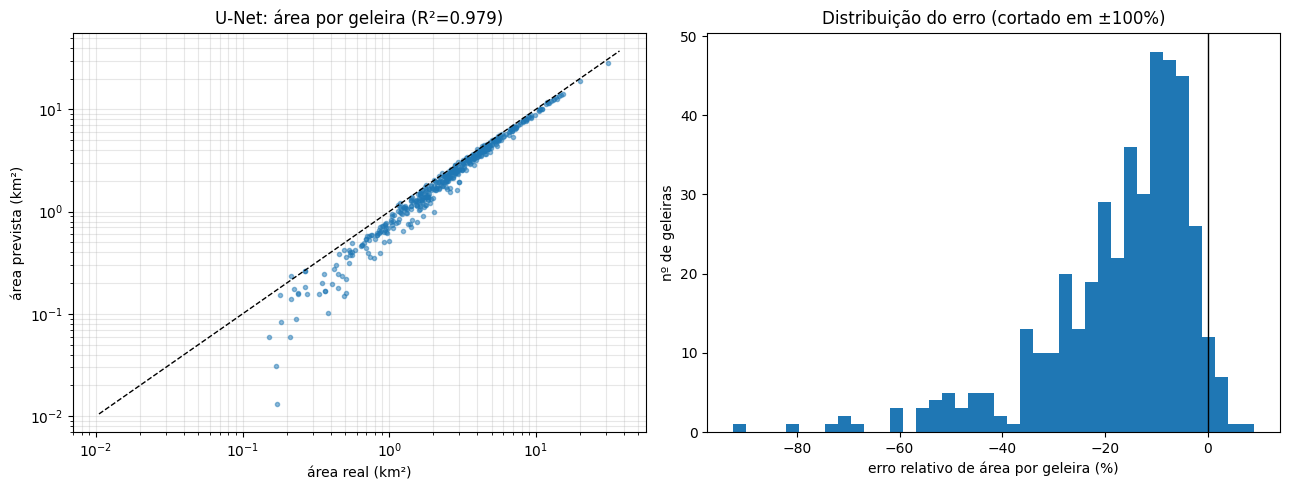

In [ ]:
def area_por_geleira(modelo, fold='fold_test', limiar=0.5):
    modelo.eval()
    caminhos = datasets[fold].caminhos
    loader = loaders[fold]

    # Coordenadas de cada patch (para alinhar os patches de uma mesma geleira)
    linhas = []
    for c in tqdm(caminhos, desc='Lendo coordenadas', leave=False):
        with xr.open_dataset(c, engine='netcdf4', cache=False) as ds:
            xs, ys = ds['x'].values, ds['y'].values
        linhas.append((re.match(r'^(g_\d+)_patch_', c.stem).group(1),
                       float(xs[0]), float(ys[0]), float(xs[1] - xs[0]), float(ys[1] - ys[0])))
    meta = pd.DataFrame(linhas, columns=['entry_id', 'x0', 'y0', 'dx', 'dy'])
    g = meta.groupby('entry_id')
    refx = g.x0.transform('max' if meta.dx.iloc[0] < 0 else 'min')
    refy = g.y0.transform('max' if meta.dy.iloc[0] < 0 else 'min')
    meta['ox'] = np.rint((meta.x0 - refx) / meta.dx).astype(int)
    meta['oy'] = np.rint((meta.y0 - refy) / meta.dy).astype(int)
    km2_pixel = abs(meta.dx.iloc[0] * meta.dy.iloc[0]) / 1e6

    # Inferência: média das probabilidades nas sobreposições (cada pixel é contado uma só vez)
    mosa, k = {}, 0
    with torch.no_grad():
        for imagens, alvos in tqdm(loader, desc=f'Inferência {fold}', leave=False):
            H, W = alvos.shape[-2:]
            if not mosa:
                for e, gg in meta.groupby('entry_id'):
                    s = (int(gg.oy.max()) + H, int(gg.ox.max()) + W)
                    mosa[e] = dict(P=np.zeros(s, np.float32), N=np.zeros(s, np.float32), G=np.zeros(s, np.uint8))
            with torch.autocast(device_type=device.type, enabled=USAR_AMP):
                logits = modelo(imagens.to(device))
            p = torch.softmax(logits.float(), 1)[:, 1].cpu().numpy()
            valido = (alvos != IGNORE_INDEX).numpy().astype(np.float32)
            real = (alvos == 1).numpy().astype(np.uint8)
            for b in range(p.shape[0]):
                r = meta.iloc[k]; m = mosa[r.entry_id]
                sl = (slice(r.oy, r.oy + H), slice(r.ox, r.ox + W))
                m['P'][sl] += p[b] * valido[b]; m['N'][sl] += valido[b]; m['G'][sl] = np.maximum(m['G'][sl], real[b]); k += 1

    # Tabela por geleira
    saida = []
    for e, m in mosa.items():
        V = m['N'] > 0
        pred = (np.divide(m['P'], m['N'], out=np.zeros_like(m['P']), where=V) >= limiar) & V
        G = m['G'] == 1; tp = (pred & G).sum()
        saida.append(dict(entry_id=e, area_real_km2=G.sum() * km2_pixel, area_prev_km2=pred.sum() * km2_pixel,
                          iou=tp / max(pred.sum() + G.sum() - tp, 1)))
    df = pd.DataFrame(saida)
    df['erro_rel_pct'] = 100 * (df.area_prev_km2 - df.area_real_km2) / df.area_real_km2.where(df.area_real_km2 > 0)
    return df

df_geleiras = area_por_geleira(modelo_unet, 'fold_test')
df_geleiras.to_csv(OUTPUT_DIR / 'areas_por_geleira_teste.csv', index=False)

# métricas de área
r, p = df_geleiras.area_real_km2.values, df_geleiras.area_prev_km2.values
r2 = 1 - ((p - r) ** 2).sum() / ((r - r.mean()) ** 2).sum()
print(f'Geleiras no teste: {len(df_geleiras)}')
print(f'Área real total: {r.sum():.2f} km² | prevista: {p.sum():.2f} km² | viés: {100*(p.sum()-r.sum())/r.sum():+.2f}%')
print(f'MAE: {np.abs(p-r).mean():.3f} km² | WAPE: {100*np.abs(p-r).sum()/r.sum():.2f}% | R²: {r2:.3f} | IoU médio por geleira: {df_geleiras.iou.mean():.3f}')

# gráfico: previsto x real (log-log) + histograma do erro relativo
d = df_geleiras[(df_geleiras.area_real_km2 > 0) & (df_geleiras.area_prev_km2 > 0)]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].loglog(d.area_real_km2, d.area_prev_km2, '.', alpha=.5)
lim = [d[['area_real_km2', 'area_prev_km2']].min().min() * .8, d[['area_real_km2', 'area_prev_km2']].max().max() * 1.2]
ax[0].plot(lim, lim, 'k--', lw=1)
ax[0].set(xlabel='área real (km²)', ylabel='área prevista (km²)', title=f'U-Net: área por geleira (R²={r2:.3f})')
ax[0].grid(alpha=.3, which='both')
ax[1].hist(df_geleiras.erro_rel_pct.dropna().clip(-100, 100), bins=40); ax[1].axvline(0, color='k', lw=1)
ax[1].set(xlabel='erro relativo de área por geleira (%)', ylabel='nº de geleiras', title='Distribuição do erro (cortado em ±100%)')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'areas_previsto_vs_real.png', dpi=150, bbox_inches='tight'); plt.show()

metricas_area = {
    'geleiras': len(df_geleiras),
    'area_real_total_km2': float(r.sum()),
    'area_prev_total_km2': float(p.sum()),
    'mae_km2': float(np.abs(p-r).mean()),
    'wape_pct': float(100*np.abs(p-r).sum()/r.sum()) if r.sum() > 0 else None,
    'r2': float(r2),
    'iou_medio_por_janela': float(df_geleiras.iou.mean()),
    'escopo': 'Mascaras binarias nas janelas amostradas; sobreposicoes removidas dentro de cada grupo entry_id. Nao equivale ao inventario completo por ID.',
}
salvar_json(OUTPUT_DIR / 'metricas_area.json', metricas_area)


# 19 — Exportar o melhor modelo e todos os resultados

O ZIP inclui o melhor modelo da U-Net, histórico, métricas, curvas de treinamento,
figura Satélite RGB / Gabarito / U-Net, painéis, medições e resultados de área.
Use esses arquivos para comparar manualmente com os resultados da sua SegNet.
O checkpoint de retomada fica na pasta de resultados e não entra no ZIP, como no original.
Para persistir o progresso entre sessões do Colab, copie a pasta de resultados para seu Drive.


In [ ]:
import zipfile
from google.colab import files

arquivo_zip = (
    OUTPUT_DIR.parent
    / f'unet_split1_metrificado_{RUN_ID}.zip'
)

with zipfile.ZipFile(
    arquivo_zip,
    'w',
    compression=zipfile.ZIP_STORED,
) as pacote:

    for caminho in sorted(OUTPUT_DIR.rglob('*')):
        if (
            caminho.is_file()
            and caminho.suffix != '.tmp'
            and caminho != caminho_ultimo
        ):
            pacote.write(
                caminho,
                arcname=str(caminho.relative_to(OUTPUT_DIR)),
            )

print('Resultados:', arquivo_zip)
files.download(str(arquivo_zip))

Resultados: unet_split1_metrificado_20261015T170636Z_05c22191.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>